# 4r_residual_migration: net migration by cohort from population change and deaths, 2011 Tohoku and 2016 Kumamoto

3r measured migration directly, but the migration report only gives municipal age detail from 2014. This notebook estimates **net migration as a residual** instead. For a group of people (a cohort) between two population counts:

> **net migration = population at the end − population at the start + deaths in between**

Whatever change births and deaths can't explain must be people moving in or out. This needs only population by age and deaths by age, so it works for the 2011 earthquake too. Deaths are taken out explicitly, so tsunami deaths are not mistaken for out-migration.

**Municipalities:** all listed in `dt/analysis_original_data.xlsx` (sheet `1_市町村一覧`):
- **Tohoku:** 123, listed under 東日本 (岩手 33, 宮城 34) and 福島 (56).
- **Kumamoto:** 45, listed under 熊本.

**Window:** ±5 years.

| | Population counts | Baseline (last count before the quake) | Quake interval |
|---|---|---|---|
| Tohoku | 2006-03-31 … 2016-01-01 | 2010-03-31 | 2010-03-31 → 2011-03-31 (the quake on 3/11 is 20 days before its end) |
| Kumamoto | 2011-03-31 … 2021-01-01 | 2016-01-01 | 2016-01-01 → 2017-01-01 |

**Data**
- **Population:** `dt/jumin_age_sex_5yr_long.qs2` (住民基本台帳), Japanese residents, both sexes.
- **Deaths:** `dt/deaths_age_sex_5yr_long.qs2`, built by `src/build_deaths_age.R` from 人口動態統計 (確定数, 保管統計表 都道府県編 死亡第1表).
  - Deaths of Japanese nationals by place of residence, calendar year, 5-year age bands.

**Method** (details and caveats in section 2 and `doc/caution.md`)
1. Split population and deaths into single years of age with `ungroup::pclm()`, as in 3r.
2. **Match deaths to the intervals between counts.** Counts are on 3/31 up to 2012 and on 1/1 from 2013, while deaths are by calendar year. For Tohoku, the 2011 excess deaths are placed in the interval that contains 3/11.
3. **Compute the residual for each single-year cohort:** NM = P(end, *x*+1) − P(start, *x*) + deaths of that cohort. Deaths are split between ages as in 3r (Lexis).
4. **Rate:** net migration ÷ the cohort's population at the start of the interval, per 1,000 per year. Each interval is computed on its own.
5. **Cohorts and groups:** cohorts are the 5-year age groups at the baseline, followed as they age (2006–2009 or 2011–2015 trace them back). The groups are:
   - Tohoku: 岩手・宮城 with 全壊率 ≥ 1; 福島 municipalities with an evacuation order (避難指示); the other listed municipalities.
   - Kumamoto: the 3r groups.

**Validation:** for Kumamoto 2014–2020, figure 6 compares the residual with the directly reported migration (Japanese movers, 3r).

Figures are written to `res/` as `4r_<NN>_<item>.png` via `show_save()`; tables are shown here only. The pclm fits are cached in `output/4r_pclm_cache.qs2`; delete it to refit.

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
  library(ungroup)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"

nb_prefix <- "4r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}
top_age <- 105

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Population: Basic Resident Register (住民基本台帳), Japanese residents. Deaths: Vital Statistics (人口動態統計), ",
                   "Japanese, by residence. Net migration = residual (population change + deaths).")

# One entry per disaster: population count years (labels as in the 住基 data),
# baseline count and the quake interval (identified by its starting count).
events <- list(
  tohoku   = list(title = "2011 Great East Japan Earthquake", groups = c("東日本", "福島"),
                  counts = 2006:2016, base = 2010, quake_start = 2010),
  kumamoto = list(title = "2016 Kumamoto Earthquake", groups = "熊本",
                  counts = 2011:2021, base = 2016, quake_start = 2016)
)

In [2]:
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 %in% c("東日本", "福島", "熊本")) |>
  transmute(event = ifelse(災害 == "熊本", "kumamoto", "tohoku"),
            code = 市町村コード, muni = 市町村, pref = 県, short = sub("^.*郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`),
            evacuation = 避難指示あり %in% c("TRUE", "True", "1")) |>
  mutate(group = case_when(
    event == "tohoku" & pref == "福島県" & evacuation ~ "福島 避難指示 (evacuation order)",
    event == "tohoku" & pref != "福島県" & zenkai_rate >= 1 ~ "岩手・宮城 全壊率 ≥ 1",
    event == "tohoku" ~ "Other listed (Tohoku)",
    zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)",
    code == "43100" ~ "熊本市",
    TRUE ~ "Other listed (Kumamoto)"))
group_levels <- list(
  tohoku = c("岩手・宮城 全壊率 ≥ 1", "福島 避難指示 (evacuation order)", "Other listed (Tohoku)"),
  kumamoto = c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed (Kumamoto)"))
group_cols <- c(setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels$tohoku),
                setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels$kumamoto))

study |> count(event, group) |> as.data.frame()
study |> filter(event == "tohoku", zenkai_rate >= 1 | evacuation) |>
  arrange(group, desc(zenkai_rate)) |> select(group, pref, short, zenkai_rate) |>
  mutate(zenkai_rate = round(zenkai_rate, 2)) |> as.data.frame()

event,group,n
<chr>,<chr>,<int>
kumamoto,High damage (全壊率 ≥ 1),5
kumamoto,Other listed (Kumamoto),39
kumamoto,熊本市,1
tohoku,Other listed (Tohoku),91
tohoku,岩手・宮城 全壊率 ≥ 1,22
tohoku,福島 避難指示 (evacuation order),10


group,pref,short,zenkai_rate
<chr>,<chr>,<chr>,<dbl>
Other listed (Tohoku),福島県,新地町,5.20
Other listed (Tohoku),福島県,相馬市,2.63
Other listed (Tohoku),福島県,いわき市,2.27
Other listed (Tohoku),福島県,国見町,1.84
Other listed (Tohoku),福島県,矢吹町,1.62
Other listed (Tohoku),福島県,須賀川市,1.55
Other listed (Tohoku),福島県,鏡石町,1.32
Other listed (Tohoku),福島県,天栄村,1.11
岩手・宮城 全壊率 ≥ 1,宮城県,女川町,28.58


In [3]:
pop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計") |>
  inner_join(study |> select(code, event), by = "code") |>
  filter(mapply(function(e, y) y %in% events[[e]]$counts, event, year)) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, event, year, ref_date, age_band, n = pop)

death_years <- list(tohoku = 2006:2015, kumamoto = 2011:2020)
dth5 <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, sex == "計") |>
  inner_join(study |> select(code, event), by = "code") |>
  filter(mapply(function(e, y) y %in% death_years[[e]], event, year)) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, event, year, age_band, n)

# Coverage, and deaths of unknown age (dropped: they cannot be placed in a cohort)
bind_rows(pop5 |> filter(age_band == "total") |> mutate(series = "population"),
          dth5 |> filter(age_band == "total") |> mutate(series = "deaths")) |>
  group_by(event, series) |>
  summarise(municipalities = n_distinct(code), years = paste(range(year), collapse = "–"),
            code_years = n(), total = sum(n), .groups = "drop") |>
  left_join(dth5 |> filter(age_band == "unknown") |> group_by(event) |>
              summarise(series = "deaths", unknown_age = sum(n)), by = c("event", "series")) |>
  as.data.frame()

event,series,municipalities,years,code_years,total,unknown_age
<chr>,<chr>,<int>,<chr>,<int>,<dbl>,<dbl>
kumamoto,deaths,45,2011–2020,450,209136,3
kumamoto,population,45,2011–2021,495,19712460,NA
tohoku,deaths,123,2006–2015,1230,538948,4
tohoku,population,123,2006–2016,1353,50948476,NA


## 1. Single years of age with `ungroup`

`pclm()` as in 3r, with one change for **population**: pclm is given the **national single-year Japanese population** at the same date as an offset (人口推計, 1 October, shifted to each count date; `src/build_natpop.R`).

**Why the change:** the residual subtracts two single-year distributions a year apart, so it is very sensitive to sharp differences in cohort size that 5-year bands hide. Plain pclm smooths them away. The worst case is the small 1945–46 birth cohorts next to the 1947–49 baby boom. With plain pclm it produced a spurious ±60 per 1,000 swing at ages 60–69 in every group and period.

**How it works:**
- With the offset, pclm smooths only the municipal/national ratio, so the cliffs come from the national shape.
- The result is rescaled so every published band total is kept exactly.
- If an offset fit fails (non-positive values), the national within-band shares are used instead; the table after the fits counts how often.
- **Deaths** use plain pclm. They are added, not differenced, so the cliffs barely matter.
- Zero bands are set to 1e-4 as the package advises.

- **Population:** the top band is 80+ through 2014 and 100+ from 2015.
- **Deaths:** the top band is 100+.

Figure 1 shows the death fits for three cases: 女川町 in 2011 (the tsunami: deaths at every age), 益城町 in 2016, and a small village. Deaths in a small place are a handful per year, so its curve is a smooth guess.

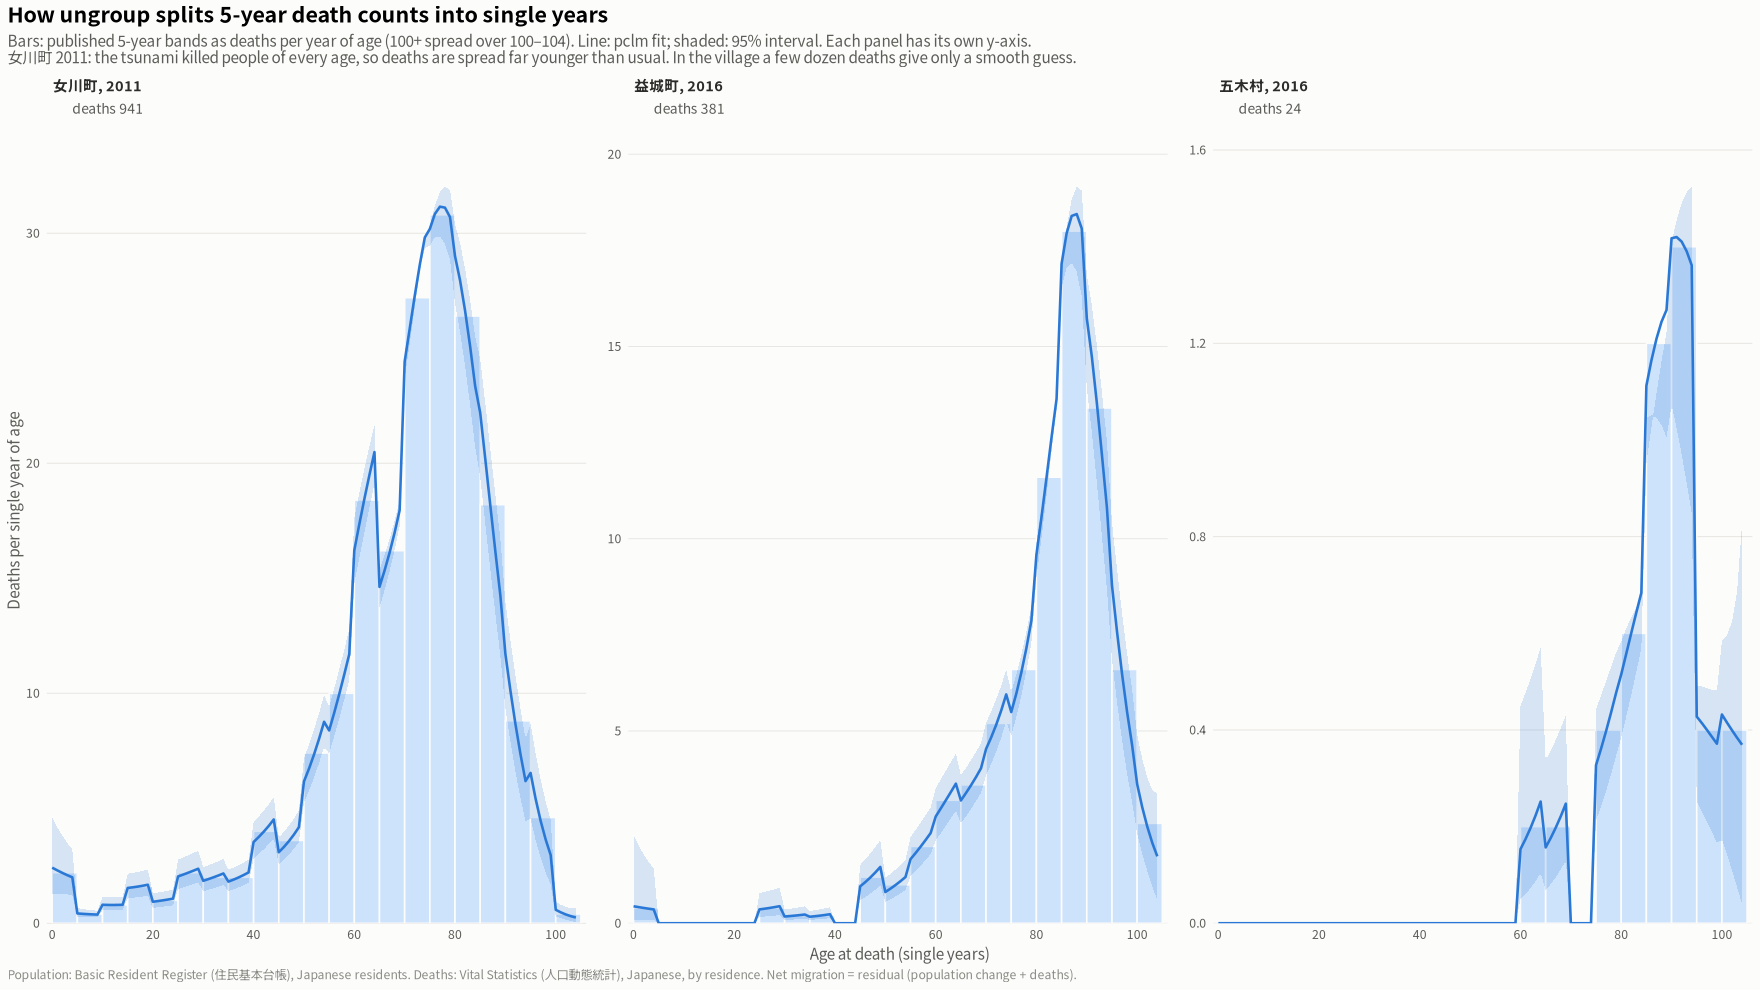

In [4]:
band_table <- function(bands, counts) {
  keep <- !bands %in% c("total", "unknown")
  if (any(bands == "80_84")) keep <- keep & bands != "80+"
  tibble(band = bands[keep], n = counts[keep]) |>
    mutate(lower = as.integer(sub("[_+].*", "", band))) |>
    arrange(lower) |>
    mutate(upper = lead(lower, default = top_age))
}
# National Japanese population by single year (1 October, thousands), the
# within-band shape: src/build_natpop.R. 100+ is spread over 100-104.
nat <- readr::read_csv(file.path(root, "dt/natpop_japanese_single_year.csv"), show_col_types = FALSE)
N <- function(y) { v <- nat$pop[nat$year == y]; c(v[1:100], v[101] * c(0.4, 0.27, 0.17, 0.10, 0.06)) }
older <- function(v) c(v[1], v[-length(v)])          # shift by one year of age
# Shape at a count date: 31 March y is half a year after 1 October y-1, 1 January y a quarter
offset_count <- function(y, ref) { a <- N(y - 1); w <- if (ref == "01-01") 0.75 else 0.5; w * a + (1 - w) * older(a) }

# Plain pclm smooths away cohort-size cliffs that 5-year bands hide (the small
# 1945-46 births next to the 1947-49 boom, 1966). For population, pclm is run
# with the national single-year shape at the same date as offset: it then
# smooths the municipal/national ratio, so the cliffs come from the national
# shape. Every fit is rescaled within each band to keep the published band
# totals. If an offset fit misbehaves (non-positive values), the national
# within-band shares are used instead. Deaths use plain pclm.
ungroup_bands <- function(bands, counts, shape = NULL) {
  b <- band_table(bands, counts)
  ages <- 0:(top_age - 1)
  band <- findInterval(ages, b$lower)
  if (sum(b$n) == 0) return(tibble(age = ages, fit = 0, lo = 0, hi = 0, lambda = NA_real_, method = "zero"))
  m <- pclm(x = b$lower, y = pmax(b$n, 1e-4), nlast = top_age - max(b$lower),
            offset = shape, verbose = FALSE)
  k <- if (is.null(shape)) 1 else shape
  raw <- unname(fitted(m)) * k
  method <- if (is.null(shape)) "pclm" else "pclm + national offset"
  lo <- unname(m$ci$lower) * k; hi <- unname(m$ci$upper) * k
  if (!is.null(shape) && (any(!is.finite(raw)) || any(raw <= 0))) {
    raw <- shape; lo <- hi <- shape; method <- "national shares"
  }
  scale <- (b$n / pmax(tapply(raw, band, sum), 1e-12))[band]
  tibble(age = ages, fit = raw * scale, lo = lo * scale, hi = hi * scale,
         lambda = unname(m$smoothPar["lambda"]), method = method)
}

demo_cases <- tibble(code = c("04581", "43443", "43511"), year = c(2011, 2016, 2016)) |>
  left_join(study |> select(code, short), by = "code") |>
  mutate(panel = factor(sprintf("%s, %d", short, year), levels = sprintf("%s, %d", short, year)))
demo <- dth5 |>
  inner_join(demo_cases, by = c("code", "year")) |>
  group_by(panel, year) |>
  group_modify(function(g, k) bind_rows(band_table(g$age_band, g$n) |> mutate(kind = "bars"),
                                        ungroup_bands(g$age_band, g$n) |> mutate(kind = "fit"))) |>
  ungroup()

bars <- demo |> filter(kind == "bars") |> mutate(per_year = n / (upper - lower))
fit <- demo |> filter(kind == "fit")
lab <- bars |> group_by(panel) |> summarise(total = sum(n))
p1 <- ggplot() +
  geom_rect(data = bars, aes(xmin = lower, xmax = upper, ymin = 0, ymax = per_year),
            fill = "#cde2fb", colour = surface, linewidth = 0.5) +
  geom_ribbon(data = fit, aes(age, ymin = lo, ymax = hi), fill = "#2a78d6", alpha = 0.18) +
  geom_line(data = fit, aes(age, fit), colour = "#2a78d6", linewidth = 0.8) +
  geom_text(data = lab, aes(x = 4, y = Inf, label = paste0("deaths ", scales::comma(total))),
            hjust = 0, vjust = 1.4, size = 3.2, colour = ink2, family = jp_font) +
  facet_wrap(~panel, ncol = 3, scales = "free_y") +
  scale_x_continuous(breaks = seq(0, 100, 20), expand = expansion(mult = 0.01)) +
  scale_y_continuous(labels = scales::label_comma(), expand = expansion(mult = c(0, 0.12))) +
  labs(title = "How ungroup splits 5-year death counts into single years",
       subtitle = paste0("Bars: published 5-year bands as deaths per year of age (100+ spread over 100–104). Line: pclm fit; shaded: 95% interval. ",
                         "Each panel has its own y-axis.\n女川町 2011: the tsunami killed people of every age, so deaths are spread far younger than usual. ",
                         "In the village a few dozen deaths give only a smooth guess."),
       x = "Age at death (single years)", y = "Deaths per single year of age", caption = src_note) +
  base_theme()
show_save(p1, "01_ungroup_deaths", width = 16, height = 6)

In [5]:
# Single-year fits for every municipality x count (population) and x calendar
# year (deaths), plus Kumamoto 2014-2020 reported migration for the validation.
cache <- file.path(root, "output/4r_pclm_cache.qs2")
mig5 <- qs_read(file.path(root, "dt/idou_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code[study$event == "kumamoto"], level == "municipality",
         mover == "japanese", sex == "計", year %in% 2014:2020, age_band != "origin_unknown") |>
  mutate(age_band = as.character(age_band)) |>
  select(code, year, series = direction, age_band, n)
if (file.exists(cache)) {
  fits <- qs_read(cache)
} else {
  dir.create(dirname(cache), showWarnings = FALSE, recursive = TRUE)
  inputs <- bind_rows(pop5 |> transmute(code, year, series = "pop", ref = substr(ref_date, 6, 10), age_band, n),
                      dth5 |> transmute(code, year, series = "deaths", ref = NA_character_, age_band, n),
                      mig5 |> mutate(ref = NA_character_))
  t0 <- Sys.time()
  fits <- inputs |>
    group_by(code, year, series) |>
    group_modify(function(g, key) {
      if (key$series == "pop") ungroup_bands(g$age_band, g$n, offset_count(key$year, g$ref[1]))
      else ungroup_bands(g$age_band, g$n)
    }) |>
    ungroup() |>
    select(code, year, series, age, fit, method)
  message("pclm fits: ", n_distinct(paste(fits$code, fits$year, fits$series)), " in ",
          round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(fits, cache)
}
fits |> group_by(series, method) |> summarise(fits = n_distinct(paste(code, year)), total = round(sum(fit)), .groups = "drop") |> as.data.frame()

series,method,fits,total
<chr>,<chr>,<int>,<dbl>
deaths,pclm,1680,748077
in,pclm,315,501375
out,pclm,315,530604
pop,pclm + national offset,1848,70660936


## 2. Matching deaths to the intervals between counts

Population counts are on **31 March up to 2012** and on **1 January from 2013**; deaths are by **calendar year**. With single-year deaths D<sub>y</sub>(*a*) for calendar year *y*, each interval gets:

| Interval | Deaths used | Length |
|---|---|---|
| 31 Mar *y* → 31 Mar *y*+1 (up to 2012) | 0.75·D<sub>y</sub> + 0.25·D<sub>y+1</sub> | 1 year |
| 2012-03-31 → 2013-01-01 | 0.75·D<sub>2012</sub> | 0.75 year |
| 1 Jan *y* → 1 Jan *y*+1 (2013+) | D<sub>y</sub> | 1 year |

- **Tohoku, 2011:** the 2011 deaths are split into a usual level, B = mean(D<sub>2009</sub>, D<sub>2010</sub>) at each age, and the excess, E = D<sub>2011</sub> − B.
  - The usual part follows the rule above.
  - The excess **E is placed in the interval 2011-03-31 → 2012-03-31**, i.e. the interval in which the register removed the victims. The quake was 3/11, but on 2011-03-31, 20 days later, most victims were still registered; death notifications, and from June 2011 presumed deaths of missing people, came later.
  - Placing E in the quake interval instead gives impossible net *in*-migration of about +70 per 1,000 there in 大槌町 and 陸前高田市 (see the check in section 3).
  - All 2011 deaths are kept; only their timing changes. The table lists the largest excesses.
- **Tsunami towns: read the quake interval and year 1 together.** How the victims and the first movers split between those two intervals differs by town. Their **sum** does not depend on this choice; section 3 shows both.
- **0.75-year interval** (2012-03-31 → 2013-01-01): only three-quarters of each cohort has a birthday in it. The end population of the cohort aged *x* is approximated as 0.75·P(*x*+1) + 0.25·P(*x*), and the rate is annualised (÷ 0.75).
- **Missing persons:** they leave the register, and enter the death statistics, only when a death is registered. Some 2011 tsunami deaths of missing people were registered later, so they can show up as later deaths or as out-migration.

In [6]:
P <- fits |> filter(series == "pop") |> select(code, count = year, age, P = fit)
D <- fits |> filter(series == "deaths") |> select(code, year, age, D = fit)
Dw <- D |> pivot_wider(names_from = year, values_from = D, names_prefix = "D")
dget <- function(y) Dw[[paste0("D", y)]]

# Deaths per interval, keyed by the interval's starting count year
interval_deaths <- function(start) {
  if (start <= 2011) {
    d <- 0.75 * dget(start) + 0.25 * dget(start + 1)
  } else if (start == 2012) {
    d <- 0.75 * dget(2012)
  } else {
    d <- dget(start)
  }
  tibble(code = Dw$code, age = Dw$age, start = start, Dint = d)
}
tohoku_codes <- study$code[study$event == "tohoku"]
# Interval that receives the 2011 excess deaths: 2011 = 2011-03-31 -> 2012-03-31,
# when the register removed the victims (see the text above and the check below)
if (!exists("excess_to")) excess_to <- 2011
# Tohoku 2011: usual level B and excess E
B <- 0.5 * (dget(2009) + dget(2010))
E <- dget(2011) - B
starts <- 2006:2020   # interval starting counts used by either event
DI <- bind_rows(lapply(starts, function(s) {
  if (s %in% 2010:2011) {
    d <- interval_deaths(s)
    tt <- d$code %in% tohoku_codes & !is.na(B)
    if (s == 2010) d$Dint[tt] <- (0.75 * dget(2010) + 0.25 * B + (excess_to == 2010) * E)[tt]
    if (s == 2011) d$Dint[tt] <- (0.75 * B + 0.25 * dget(2012) + (excess_to == 2011) * E)[tt]
    d
  } else interval_deaths(s)
})) |> filter(!is.na(Dint))

# 2011 excess deaths per Tohoku municipality (top 15)
tibble(code = Dw$code, age = Dw$age, E = E, D2011 = dget(2011), B = B) |>
  filter(code %in% tohoku_codes) |>
  group_by(code) |>
  summarise(deaths_2011 = round(sum(D2011)), usual = round(sum(B)), excess = round(sum(E)),
            excess_under_40 = round(sum(E[age < 40])), .groups = "drop") |>
  left_join(study |> select(code, pref, short, zenkai_rate), by = "code") |>
  arrange(desc(excess)) |>
  mutate(zenkai_rate = round(zenkai_rate, 2)) |>
  select(pref, short, zenkai_rate, deaths_2011, usual, excess, excess_under_40) |>
  head(15) |> as.data.frame()

pref,short,zenkai_rate,deaths_2011,usual,excess,excess_under_40
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
宮城県,石巻市,12.25,5692,1889,3803,621
岩手県,陸前高田市,15.67,1996,322,1674,256
宮城県,気仙沼市,11.32,2213,949,1264,142
岩手県,大槌町,19.12,1414,234,1180,121
宮城県,東松島市,12.73,1481,434,1046,160
岩手県,釜石市,7.33,1617,640,976,82
宮城県,名取市,3.88,1476,539,937,149
宮城県,女川町,28.58,941,138,803,60
岩手県,山田町,14.19,1023,287,736,74


## 3. Residual net migration per cohort

For a single-year cohort aged *x* at the start of an interval:

> NM = P<sub>end</sub>(*x*+1) − P<sub>start</sub>(*x*) + ½·(D(*x*) + D(*x*+1))

For the 0.75-year interval, P<sub>end</sub> is 0.75·P(*x*+1) + 0.25·P(*x*). Each cohort is labelled by its age at the event's baseline count. Rates per 1,000 per year are ΣNM ÷ ΣP<sub>start</sub> ÷ length, pooled over the ages of a cohort bin and over the municipalities of a group.

**Check:** summed over all cohorts, the residual must equal the municipality's total population change plus its deaths, minus what no starting cohort covers: newborns and half of the infant deaths. The `unexplained` column should be close to 0.

In [7]:
span_of <- function(s) ifelse(s == 2012, 0.75, 1)
res1 <- P |>
  rename(start = count, P0 = P) |>
  inner_join(P |> transmute(code, start = count - 1, age = age - 1, P1_next = P), by = c("code", "start", "age")) |>
  left_join(P |> transmute(code, start = count - 1, age, P1_same = P), by = c("code", "start", "age")) |>
  inner_join(DI |> group_by(code, start) |> arrange(age, .by_group = TRUE) |>
               mutate(Dc = 0.5 * (Dint + lead(Dint, default = 0))) |> ungroup() |>
               select(code, start, age, Dc), by = c("code", "start", "age")) |>
  inner_join(study |> select(code, event, short, group), by = "code") |>
  filter(mapply(function(e, s) s %in% head(events[[e]]$counts, -1), event, start)) |>
  mutate(span = span_of(start),
         P1 = ifelse(start == 2012, 0.75 * P1_next + 0.25 * coalesce(P1_same, P1_next), P1_next),
         NM = P1 - P0 + Dc)

# Check against the municipality totals. Summed over cohorts, the residual
# must equal population change + deaths minus what no starting cohort covers:
# newborns (end population aged 0; x 0.75 for the 0.75-year interval) and
# half the infant deaths (Lexis split). Ages 104+ are negligible.
chk <- res1 |>
  group_by(event, code, start) |>
  summarise(NM_cohorts = sum(NM), .groups = "drop") |>
  left_join(P |> group_by(code, count) |> summarise(Ptot = sum(P), .groups = "drop") |>
              transmute(code, start = count, Pstart = Ptot), by = c("code", "start")) |>
  left_join(P |> group_by(code, count) |> summarise(Ptot = sum(P), P_age0 = sum(P[age == 0]), .groups = "drop") |>
              transmute(code, start = count - 1, Pend = Ptot, Pend_age0 = P_age0), by = c("code", "start")) |>
  left_join(DI |> group_by(code, start) |> summarise(Dtot = sum(Dint), D0 = sum(Dint[age == 0]), .groups = "drop"),
            by = c("code", "start"))
chk |> group_by(event) |>
  summarise(code_intervals = n(),
            residual_total = round(sum(NM_cohorts)),
            pop_change_plus_deaths = round(sum(Pend - Pstart + Dtot)),
            newborns_and_half_infant_deaths = round(sum(ifelse(start == 2012, 0.75, 1) * Pend_age0 + 0.5 * D0)),
            .groups = "drop") |>
  mutate(unexplained = pop_change_plus_deaths - residual_total - newborns_and_half_infant_deaths) |>
  as.data.frame()

event,code_intervals,residual_total,pop_change_plus_deaths,newborns_and_half_infant_deaths,unexplained
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
kumamoto,450,-29302,116901,146690,-487
tohoku,1230,-149436,184772,335403,-1195


In [8]:
# Timing check for the 2011 excess deaths, tsunami towns (岩手・宮城 全壊率 >= 1):
# net migration per 1,000 per year in the quake interval (2010) and year 1 (2011)
# with E in year 1 (used) and with E in the quake interval (alternative). The
# two-interval sum is the same either way.
Ec <- tibble(code = Dw$code, age = Dw$age, E = E) |>
  filter(code %in% tohoku_codes, !is.na(E)) |>
  group_by(code) |> arrange(age, .by_group = TRUE) |>
  mutate(Ec = 0.5 * (E + lead(E, default = 0))) |> ungroup() |> select(code, age, Ec)
res1 |>
  filter(group == "岩手・宮城 全壊率 ≥ 1", start %in% 2010:2011) |>
  left_join(Ec, by = c("code", "age")) |>
  group_by(code, short, start) |>
  summarise(P0 = sum(P0), NM = sum(NM), Ec = sum(Ec, na.rm = TRUE), .groups = "drop") |>
  mutate(alt = ifelse(start == 2010, NM + Ec, NM - Ec)) |>
  group_by(code, short) |>
  summarise(quake_used = 1000 * NM[start == 2010] / P0[start == 2010],
            year1_used = 1000 * NM[start == 2011] / P0[start == 2011],
            quake_alt = 1000 * alt[start == 2010] / P0[start == 2010],
            year1_alt = 1000 * alt[start == 2011] / P0[start == 2011],
            two_intervals_per_1000_at_baseline = 1000 * sum(NM) / P0[start == 2010], .groups = "drop") |>
  left_join(study |> select(code, zenkai_rate), by = "code") |>
  arrange(desc(zenkai_rate)) |>
  mutate(across(where(is.numeric), ~ round(.x, 1))) |>
  select(-code) |>
  as.data.frame()

short,quake_used,year1_used,quake_alt,year1_alt,two_intervals_per_1000_at_baseline,zenkai_rate
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
女川町,-42.5,-49.5,35.9,-132.2,-89.4,28.6
大槌町,-2.3,-88.0,70.6,-161.7,-89.2,19.1
南三陸町,-35.7,-49.8,4.8,-92.2,-83.4,17.6
陸前高田市,2.5,-59.0,71.4,-128.3,-56.1,15.7
山田町,-24.3,-25.5,13.4,-64.5,-48.9,14.2
山元町,-46.3,-58.6,-9.0,-98.1,-101.6,13.1
東松島市,-22.6,-13.9,1.5,-38.6,-36.1,12.7
石巻市,-6.7,-30.8,16.5,-54.3,-37.2,12.2
気仙沼市,-13.5,-26.2,3.3,-43.4,-39.1,11.3


## 4. Age profile of net migration, before / around / after (fixed age)

> **Method noise.** A one-year residual needs single-year counts at the edges of each 5-year band, and the bands don't contain that information. Where neighbouring birth cohorts differ sharply, the error of a single interval is about ±15–30 per 1,000; the national offset halves it but cannot remove it. The worst case is the war-end dip in 1944–46 births next to the 1947–49 baby boom.
>
> Two things are shown to guard against this:
> - **Noise band:** for each group and age band, the spread of the pre-quake intervals (mean ± 2 SD). A single post-quake interval outside it is a real change; one inside it may be noise.
> - **Flagged ages:** the ages the 1944–50 cohorts pass through during each window are shaded and should not be read.
>
> The protocol's target ages (0–14, 20–39) have small noise in Tohoku (SD about 1–5 per 1,000).

The same age band compared across periods, as in 3r figure 3. Each point is the residual net migration of people aged *x*–*x*+4 at the start of an interval, per 1,000 of them per year.

**Periods**
- **Before:** the intervals between the first count and the baseline.
- **Quake interval:** the interval that contains the quake.
- **After, years 1–2:** the next two intervals.
- **After, later:** the rest, i.e. years 3–5 for Tohoku and years 3–4 for Kumamoto.

**Tohoku timing:** the quake interval ends 20 days after 3/11, so most of the moves show up in **after, years 1–2**.

band,pre_sd_kumamoto,pre_sd_tohoku,cliff_kumamoto,cliff_tohoku
<fct>,<dbl>,<dbl>,<lgl>,<lgl>
0–4,3.6,1.5,FALSE,FALSE
5–9,1.6,1.9,FALSE,FALSE
10–14,4.9,4.7,FALSE,FALSE
15–19,9.0,2.6,FALSE,FALSE
20–24,15.1,3.9,FALSE,FALSE
25–29,10.4,0.7,FALSE,FALSE
30–34,4.7,2.3,FALSE,FALSE
35–39,5.9,4.7,FALSE,FALSE
40–44,4.0,6.6,FALSE,FALSE


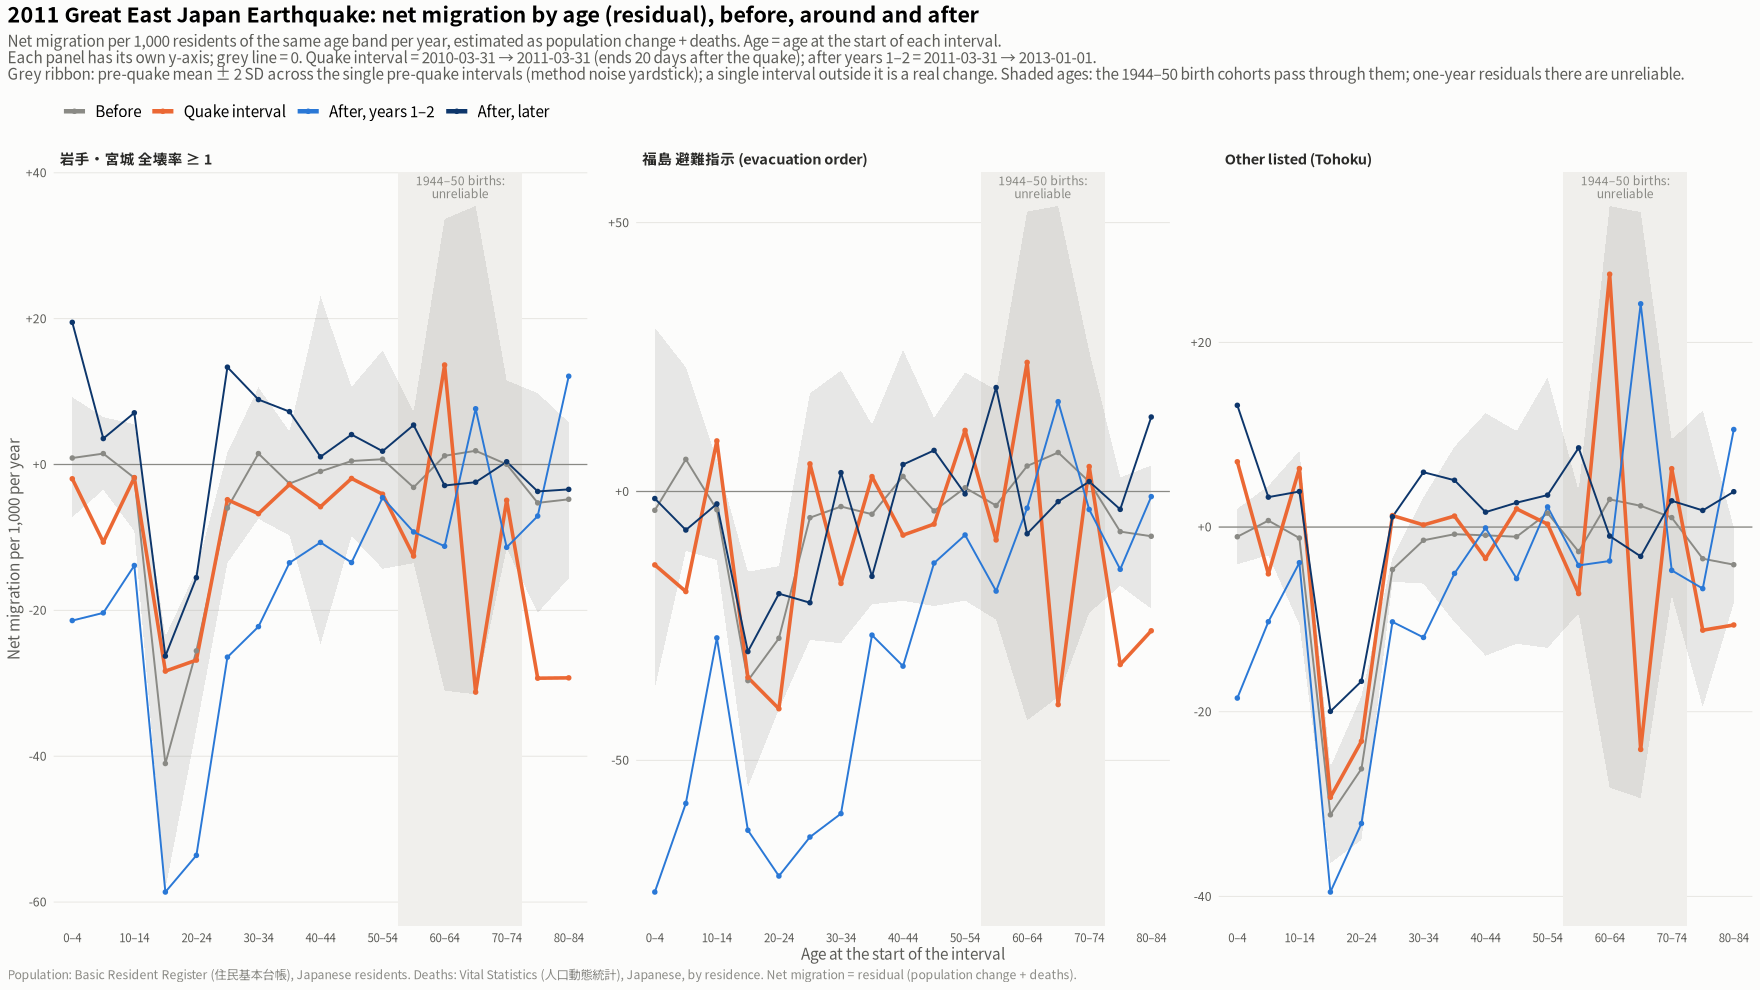

In [9]:
periods <- c("Before", "Quake interval", "After, years 1–2", "After, later")
period_cols <- setNames(c("#8a8a85", "#eb6834", "#2a78d6", "#0d366b"), periods)
bands5 <- paste0(seq(0, 80, 5), "–", seq(4, 84, 5))

res1 <- res1 |>
  mutate(q = mapply(function(e) events[[e]]$quake_start, event),
         period = factor(case_when(start < q ~ periods[1], start == q ~ periods[2],
                                   start <= q + 2 ~ periods[3], TRUE ~ periods[4]), levels = periods),
         band = factor(ifelse(age <= 84, paste0(age %/% 5 * 5, "–", age %/% 5 * 5 + 4), NA), levels = bands5))

profile <- res1 |>
  filter(!is.na(band)) |>
  group_by(event, group, period, band) |>
  summarise(rate = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")

# Method noise. A one-year residual needs single-year counts at the band edges,
# which 5-year bands do not contain; where neighbouring birth cohorts differ
# sharply the error of one interval is +-15-30 per 1,000. The yardstick is the
# year-to-year spread of the pre-quake intervals (full-year ones only), per
# group and age band: the band drawn is the pre-quake mean +- 2 SD.
noise <- res1 |>
  filter(!is.na(band), start < q, span == 1) |>
  group_by(event, group, band, start) |>
  summarise(rate = 1000 * sum(NM) / sum(P0), .groups = "drop") |>
  group_by(event, group, band) |>
  summarise(pre_mean = mean(rate), pre_sd = sd(rate), intervals = n(), .groups = "drop")

# Ages at the interval start that the 1944-1950 birth cohorts (war-end dip next
# to the 1947-49 boom) pass through during each window: flagged as unreliable.
cliff_births <- 1944:1950
cliff_bands <- lapply(events, function(ev) {
  st <- head(ev$counts, -1)
  ages <- range(outer(st, cliff_births, function(t, b) t - b - 1))
  bands5[seq(ages[1] %/% 5 + 1, min(ages[2] %/% 5 + 1, length(bands5)))]
})

# Table: noise SD by age band (per 1,000 per year), the "Other listed" groups
noise |> filter(grepl("^Other", group)) |>
  mutate(pre_sd = round(pre_sd, 1), cliff = mapply(function(e, b) b %in% cliff_bands[[e]], event, band)) |>
  select(event, band, pre_sd, cliff) |>
  pivot_wider(names_from = event, values_from = c(pre_sd, cliff)) |>
  as.data.frame()

plot_profile <- function(e) {
  dd <- profile |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  nz <- noise |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  cb <- match(cliff_bands[[e]], bands5)
  ggplot(dd, aes(band, rate, colour = period, group = period)) +
    annotate("rect", xmin = min(cb) - 0.5, xmax = max(cb) + 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
    annotate("text", x = mean(cb), y = Inf, label = "1944–50 births:\nunreliable", vjust = 1.2,
             size = 2.8, colour = ink3, family = jp_font, lineheight = 0.9) +
    geom_ribbon(data = nz, aes(x = band, ymin = pre_mean - 2 * pre_sd, ymax = pre_mean + 2 * pre_sd, group = 1),
                inherit.aes = FALSE, fill = "#8a8a85", alpha = 0.18) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(aes(linewidth = period == periods[2])) +
    geom_point(size = 1.1) +
    facet_wrap(~group, nrow = 1, scales = "free_y") +
    scale_colour_manual(values = period_cols, name = NULL) +
    scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
    scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, b, "")) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(events[[e]]$title, ": net migration by age (residual), before, around and after"),
         subtitle = paste0("Net migration per 1,000 residents of the same age band per year, estimated as population change + deaths. ",
                           "Age = age at the start of each interval.\nEach panel has its own y-axis; grey line = 0. ",
                           if (e == "tohoku") "Quake interval = 2010-03-31 → 2011-03-31 (ends 20 days after the quake); after years 1–2 = 2011-03-31 → 2013-01-01."
                           else "Quake interval = calendar 2016; after years 1–2 = 2017–2018; later = 2019–2020.",
                           "\nGrey ribbon: pre-quake mean ± 2 SD across the single pre-quake intervals (method noise yardstick); a single interval outside it is a real change. ",
                           "Shaded ages: the 1944–50 birth cohorts pass through them; one-year residuals there are unreliable."),
         x = "Age at the start of the interval", y = "Net migration per 1,000 per year", caption = src_note) +
    base_theme() +
    theme(axis.text.x = element_text(size = 7.5)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}
show_save(plot_profile("tohoku"), "02_tohoku_age_profile", width = 16, height = 6.5)

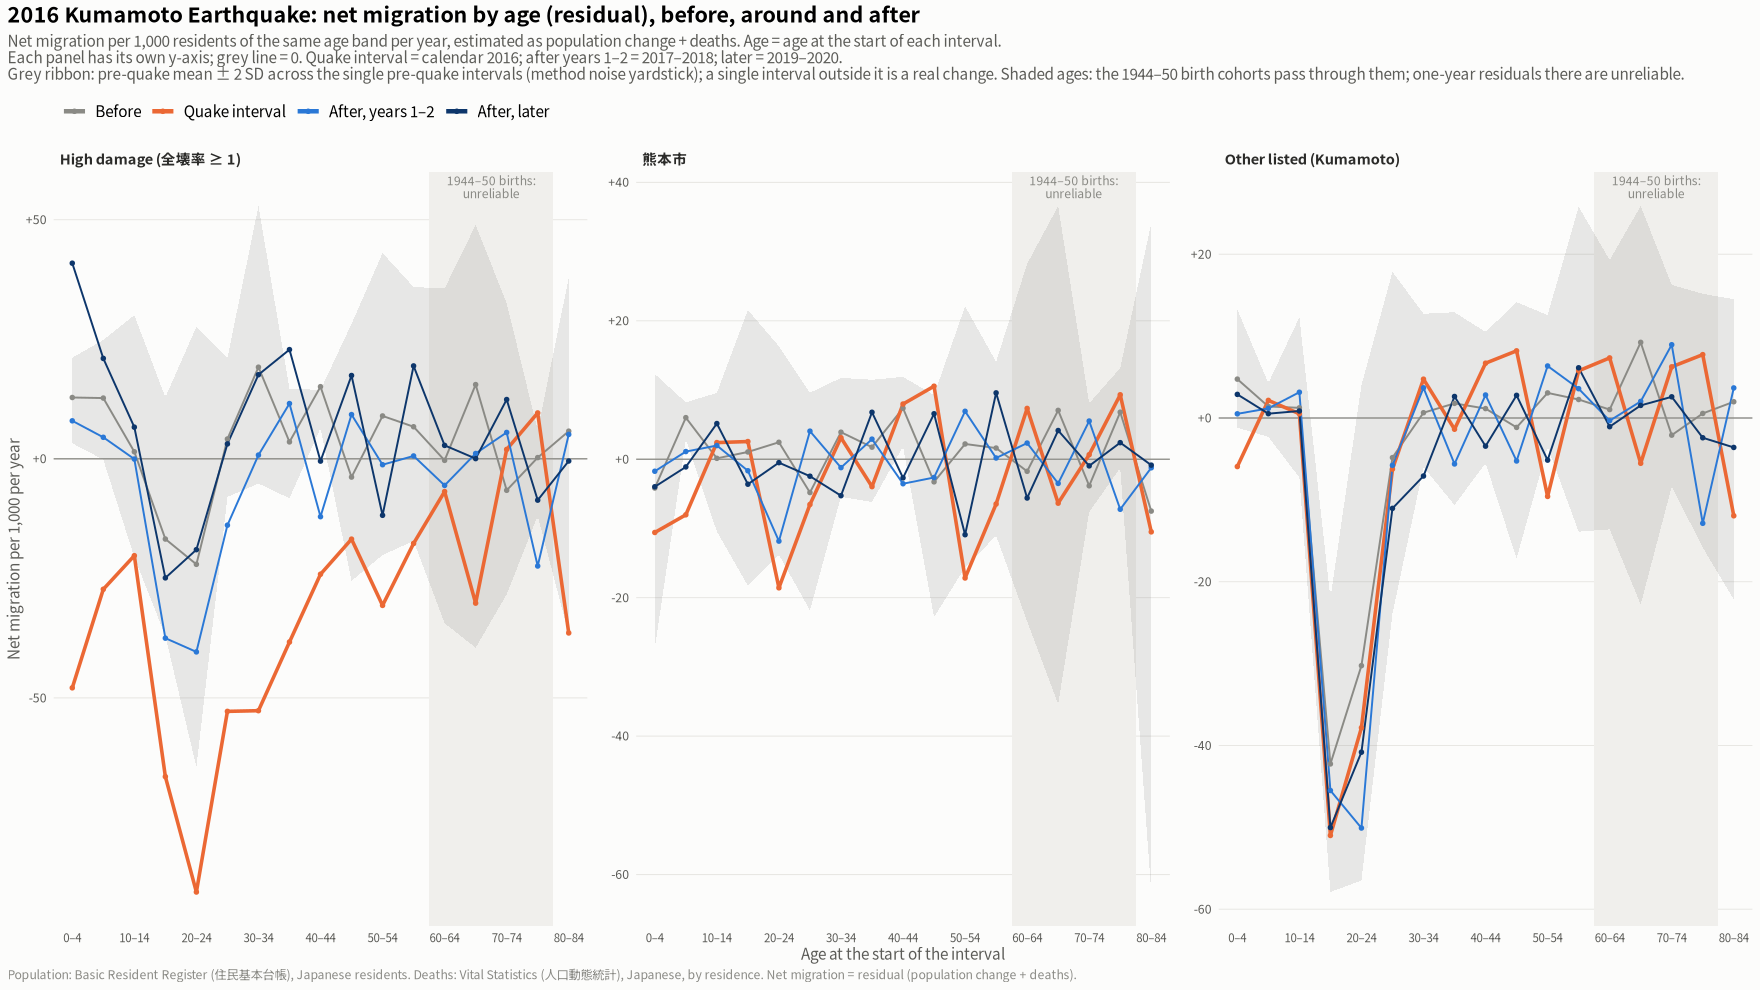

In [10]:
show_save(plot_profile("kumamoto"), "03_kumamoto_age_profile", width = 16, height = 6.5)

## 5. Cohort net migration rates (following the baseline age groups)

Cohorts are the age groups at the baseline count: 2010-03-31 for Tohoku, 2016-01-01 for Kumamoto. Each is followed as it ages. Every interval's rate = the cohort's residual net migration in that interval ÷ its population at the start of the interval, per 1,000 per year.

- **Back-cast:** intervals before the baseline (shaded) trace the same people backwards. Ages that would be below 0 are dropped.
- **Wider bins:** cohorts aged 40+ are grouped into wider bins.

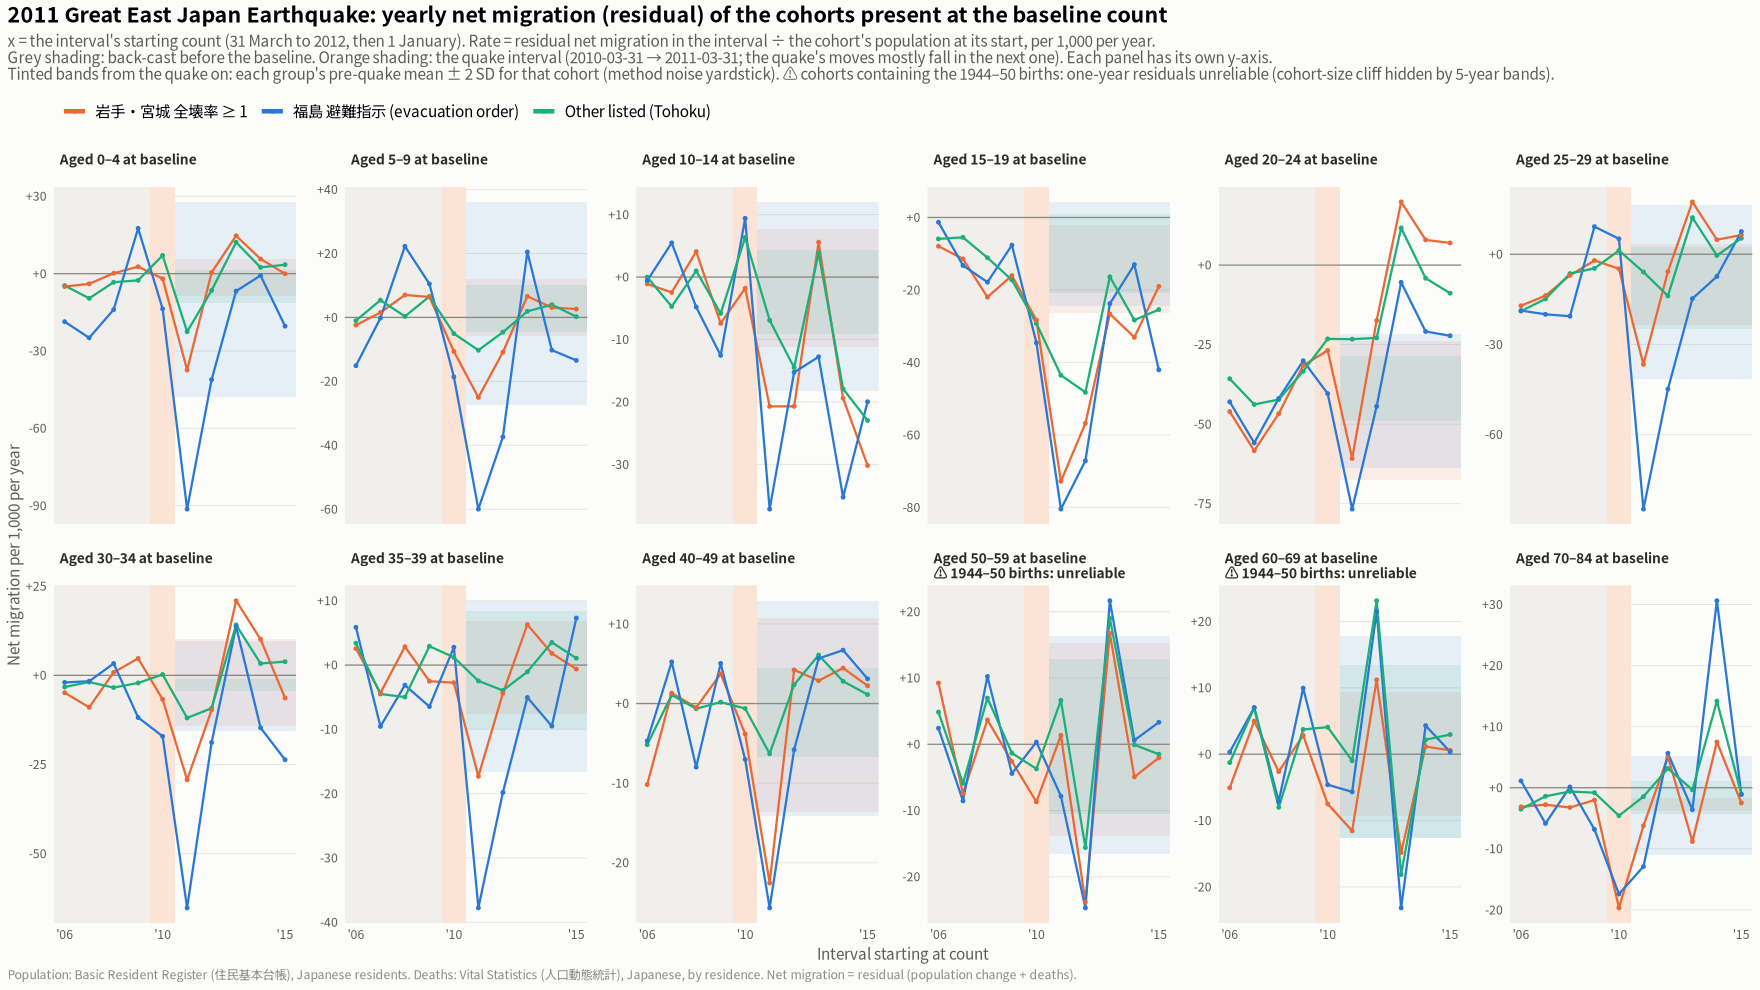

In [11]:
cohort_bins <- c(paste0(seq(0, 35, 5), "–", seq(4, 39, 5)), "40–49", "50–59", "60–69", "70–84")
cohort_of <- function(a0) {
  lab <- case_when(a0 < 40 ~ paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                   a0 < 70 ~ paste0(a0 %/% 10 * 10, "–", a0 %/% 10 * 10 + 9),
                   a0 <= 84 ~ "70–84", TRUE ~ NA_character_)
  factor(lab, levels = cohort_bins)
}
res1 <- res1 |>
  mutate(base = mapply(function(e) events[[e]]$base, event),
         a0 = age - (start - base),   # age at the baseline count
         cohort = cohort_of(a0)) |>
  filter(a0 >= 0)

cr_group <- res1 |>
  filter(!is.na(cohort)) |>
  group_by(event, group, cohort, start) |>
  summarise(rate = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")

plot_cohorts <- function(e) {
  ev <- events[[e]]
  # cohort bins containing the 1944-50 births are flagged in the panel title
  born <- function(lab) { r <- as.integer(strsplit(as.character(lab), "–")[[1]]); ev$base - rev(r) - 1 }
  flag <- sapply(cohort_bins, function(b) any(born(b)[1]:born(b)[2] %in% cliff_births))
  labs_c <- paste0("Aged ", cohort_bins, " at baseline", ifelse(flag, "\n⚠ 1944–50 births: unreliable", "\n"))
  dd <- cr_group |> filter(event == e) |>
    mutate(group = factor(group, levels = group_levels[[e]]),
           cohort_lab = factor(labs_c[match(cohort, cohort_bins)], levels = labs_c))
  # Noise band: mean +- 2 SD of the cohort's own back-cast (pre-quake, full-year) intervals
  nb <- dd |> filter(start < ev$quake_start, !(start == 2012)) |>
    group_by(group, cohort_lab) |>
    summarise(lo = mean(rate) - 2 * sd(rate), hi = mean(rate) + 2 * sd(rate), .groups = "drop")
  ggplot(dd, aes(start, rate, colour = group)) +
    geom_rect(data = nb, aes(xmin = ev$quake_start - 0.5, xmax = Inf, ymin = lo, ymax = hi, fill = group),
              inherit.aes = FALSE, alpha = 0.10) +
    scale_fill_manual(values = group_cols[group_levels[[e]]], guide = "none") +
    annotate("rect", xmin = -Inf, xmax = ev$base - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
    annotate("rect", xmin = ev$quake_start - 0.5, xmax = ev$quake_start + 0.5, ymin = -Inf, ymax = Inf,
             fill = "#fbe3d6") +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(linewidth = 0.7) +
    geom_point(size = 0.9) +
    facet_wrap(~cohort_lab, nrow = 2, scales = "free_y") +
    scale_colour_manual(values = group_cols[group_levels[[e]]], name = NULL) +
    scale_x_continuous(breaks = c(min(ev$counts), ev$base, max(ev$counts) - 1),
                       labels = function(v) paste0("'", substr(v, 3, 4))) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(ev$title, ": yearly net migration (residual) of the cohorts present at the baseline count"),
         subtitle = paste0("x = the interval's starting count (", if (e == "tohoku") "31 March to 2012, then 1 January" else "1 January from 2013",
                           "). Rate = residual net migration in the interval ÷ the cohort's population at its start, per 1,000 per year.\n",
                           "Grey shading: back-cast before the baseline. Orange shading: the quake interval",
                           if (e == "tohoku") " (2010-03-31 → 2011-03-31; the quake's moves mostly fall in the next one)." else " (calendar 2016).",
                           " Each panel has its own y-axis.\nTinted bands from the quake on: each group's pre-quake mean ± 2 SD for that cohort (method noise yardstick). ",
                           "⚠ cohorts containing the 1944–50 births: one-year residuals unreliable (cohort-size cliff hidden by 5-year bands)."),
         x = "Interval starting at count", y = "Net migration per 1,000 per year", caption = src_note) +
    base_theme() +
    theme(strip.text = element_text(size = 9)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}
show_save(plot_cohorts("tohoku"), "04_tohoku_cohort_rates", width = 18, height = 9)

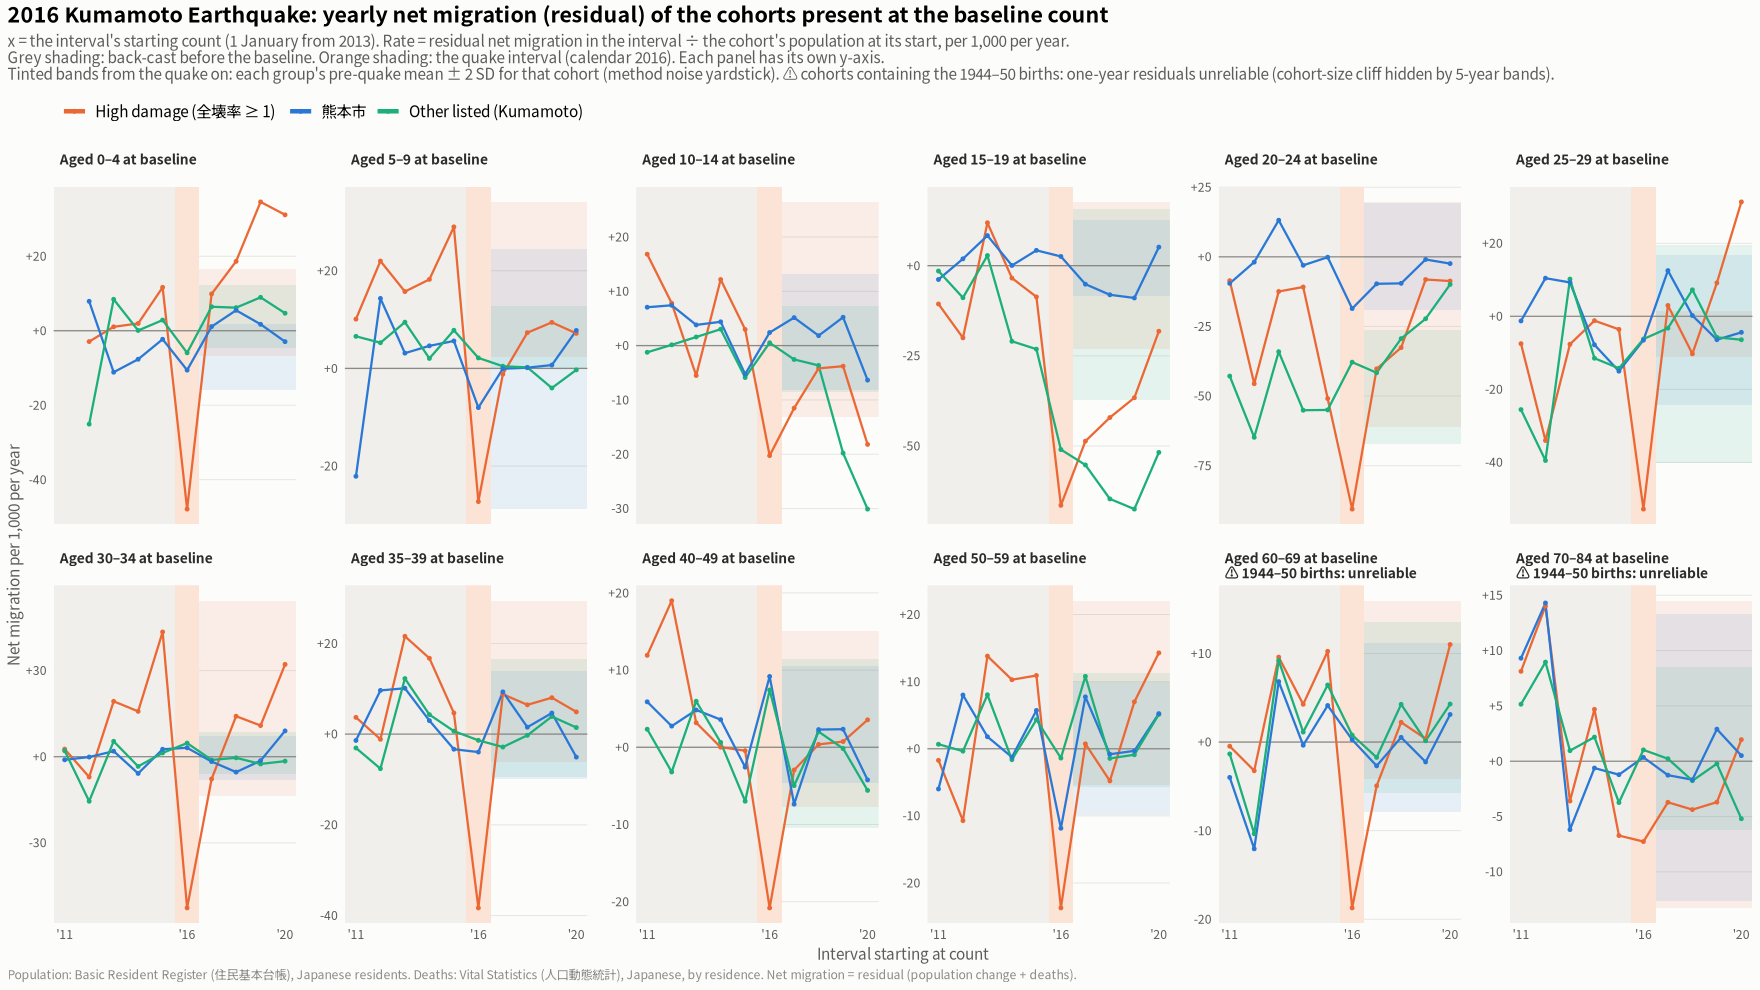

In [12]:
show_save(plot_cohorts("kumamoto"), "05_kumamoto_cohort_rates", width = 18, height = 9)

In [13]:
# Table: Tohoku cohort net rates per 1,000 per year, by group (columns = interval start)
cr_group |>
  filter(event == "tohoku") |>
  mutate(rate = round(rate, 1)) |>
  pivot_wider(names_from = start, values_from = rate) |>
  arrange(factor(group, levels = group_levels$tohoku), cohort) |>
  as.data.frame()

event,group,cohort,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
tohoku,岩手・宮城 全壊率 ≥ 1,0–4,-5.0,-3.9,0.2,2.7,-2.0,-37.4,0.4,14.7,5.7,-0.1
tohoku,岩手・宮城 全壊率 ≥ 1,5–9,-2.4,1.5,7.0,6.4,-10.6,-25.0,-10.9,6.6,3.1,2.6
tohoku,岩手・宮城 全壊率 ≥ 1,10–14,-1.1,-2.5,4.1,-7.4,-1.8,-20.7,-20.7,5.6,-19.4,-30.2
tohoku,岩手・宮城 全壊率 ≥ 1,15–19,-7.9,-11.4,-22.0,-16.0,-28.3,-72.8,-56.8,-26.6,-33.1,-19.0
tohoku,岩手・宮城 全壊率 ≥ 1,20–24,-46.1,-58.4,-46.7,-31.6,-26.8,-60.8,-17.4,19.9,7.9,7.0
tohoku,岩手・宮城 全壊率 ≥ 1,25–29,-17.1,-13.8,-7.0,-2.1,-4.8,-36.6,-5.8,17.4,4.8,6.4
tohoku,岩手・宮城 全壊率 ≥ 1,30–34,-4.9,-9.0,0.8,4.7,-6.7,-29.3,-9.7,20.9,10.1,-6.4
tohoku,岩手・宮城 全壊率 ≥ 1,35–39,2.6,-4.3,2.9,-2.5,-2.7,-17.3,-4.4,6.3,1.8,-0.6
tohoku,岩手・宮城 全壊率 ≥ 1,40–49,-10.2,1.3,-0.5,3.7,-3.8,-22.5,4.2,2.9,4.5,2.2


## 6. Validation: residual vs directly reported migration (Kumamoto, 2014–2020)

For 2014–2020 the migration report gives in- and out-migrants by age (Japanese movers, as in 3r). Population counts from 2013 are on 1 January, so each interval matches a calendar year of migration exactly.

The reported net for each cohort uses the same single-year split and Lexis rule. If the residual method works, the two should agree. They will not agree exactly, because the residual also absorbs:
- register corrections (職権記載・消除);
- moves to and from abroad (not counted in the inter-municipal migration tables);
- pclm smoothing in both series.

In [14]:
M1 <- fits |> filter(series %in% c("in", "out")) |>
  select(code, year, series, age, M = fit) |>
  group_by(code, year, series) |> arrange(age, .by_group = TRUE) |>
  mutate(Mc = 0.5 * (M + lead(M, default = 0))) |> ungroup() |>
  select(-M) |> pivot_wider(names_from = series, values_from = Mc)

val <- res1 |>
  filter(event == "kumamoto", start %in% 2014:2020, !is.na(cohort)) |>
  inner_join(M1 |> rename(start = year), by = c("code", "start", "age")) |>
  group_by(code, short, group, cohort, start) |>
  summarise(P0 = sum(P0), residual = 1000 * sum(NM) / sum(P0),
            reported = 1000 * (sum(`in`) - sum(out)) / sum(P0), .groups = "drop") |>
  mutate(group = factor(group, levels = group_levels$kumamoto))

val |>
  group_by(group) |>
  summarise(points = n(), correlation = round(cor(residual, reported), 3),
            mean_residual = round(weighted.mean(residual, P0), 1),
            mean_reported = round(weighted.mean(reported, P0), 1),
            mean_difference = round(weighted.mean(residual - reported, P0), 1), .groups = "drop") |>
  as.data.frame()

# Whole municipalities, all ages: residual vs reported net, per year
val |> group_by(start) |>
  summarise(residual = round(sum(residual * P0) / 1000), reported = round(sum(reported * P0) / 1000), .groups = "drop") |>
  rename(year = start) |> as.data.frame()

group,points,correlation,mean_residual,mean_reported,mean_difference
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
High damage (全壊率 ≥ 1),420,0.832,-2.7,-3.0,0.3
熊本市,84,0.564,-0.4,-0.5,0.2
Other listed (Kumamoto),3276,0.703,-3.8,-3.9,0.1


year,residual,reported
<dbl>,<dbl>,<dbl>
2014,-3014,-2779
2015,-3247,-3851
2016,-6981,-6553
2017,-3909,-3796
2018,-3585,-3880
2019,-4128,-4277
2020,-2652,-3726


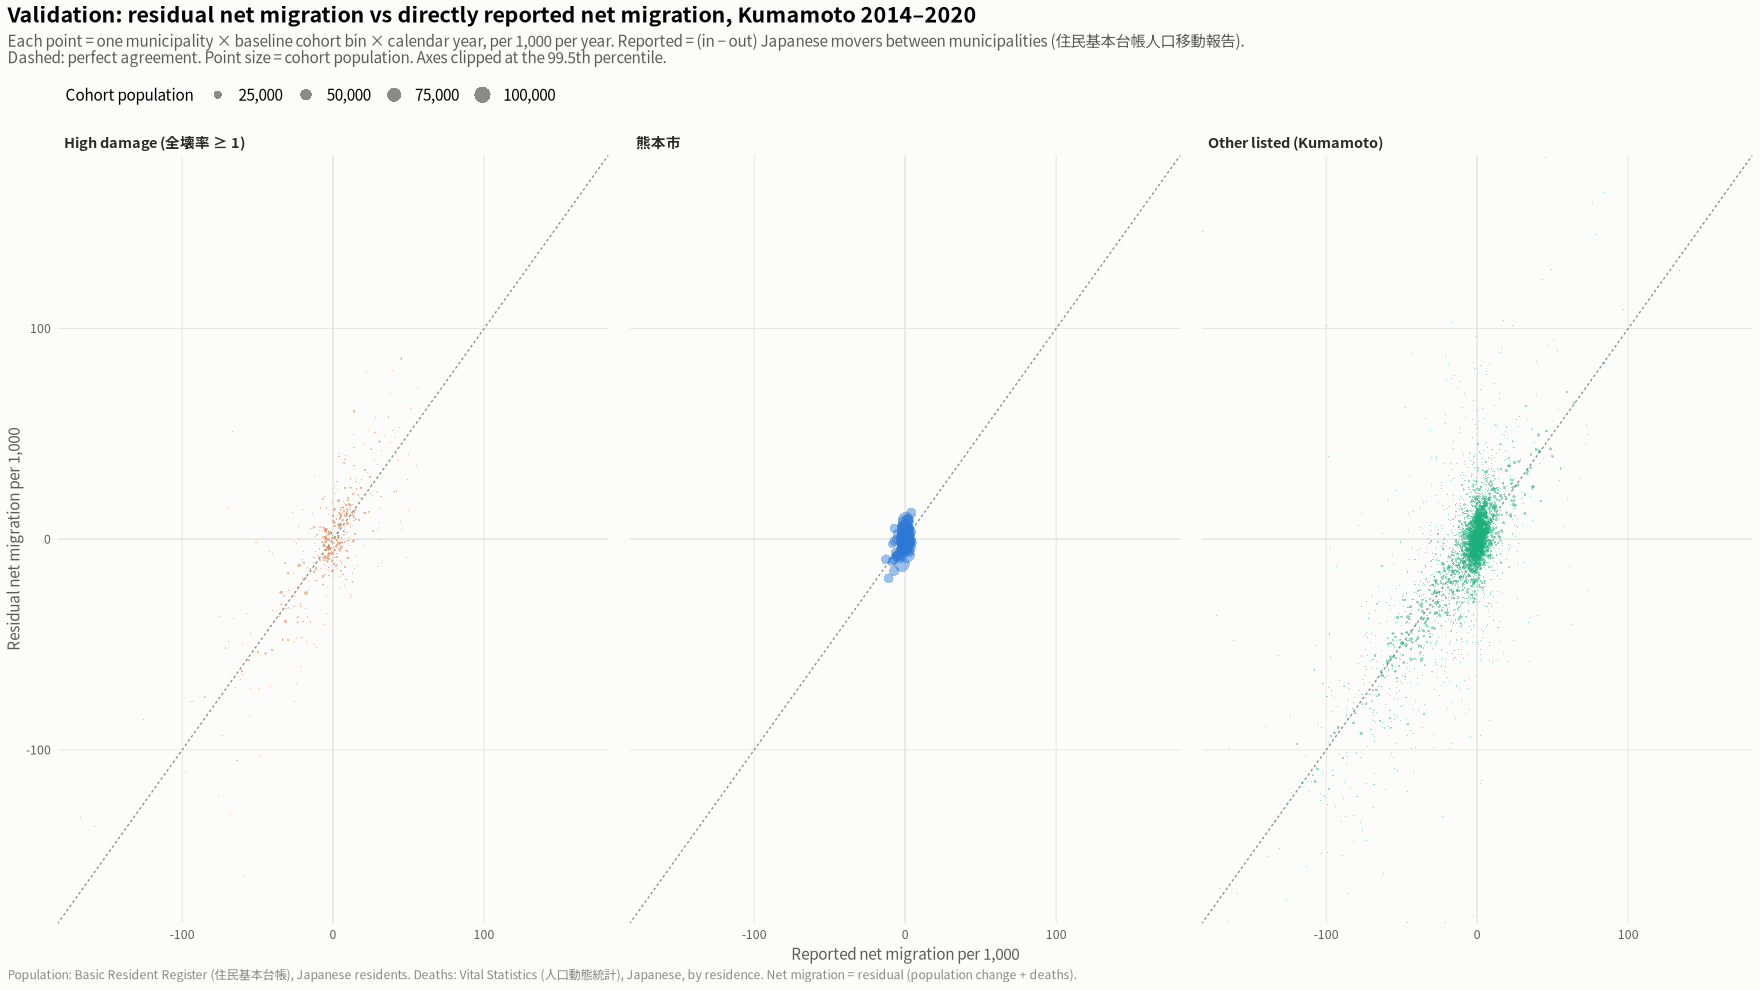

In [15]:
lim <- quantile(abs(c(val$residual, val$reported)), 0.995)
p6 <- ggplot(val, aes(reported, residual, colour = group)) +
  geom_abline(slope = 1, intercept = 0, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_hline(yintercept = 0, colour = grid_col) + geom_vline(xintercept = 0, colour = grid_col) +
  geom_point(aes(size = P0), alpha = 0.45, stroke = 0) +
  facet_wrap(~group, nrow = 1) +
  scale_colour_manual(values = group_cols[group_levels$kumamoto], guide = "none") +
  scale_size_area(max_size = 5, name = "Cohort population", labels = scales::label_comma()) +
  coord_cartesian(xlim = c(-lim, lim), ylim = c(-lim, lim)) +
  labs(title = "Validation: residual net migration vs directly reported net migration, Kumamoto 2014–2020",
       subtitle = paste0("Each point = one municipality × baseline cohort bin × calendar year, per 1,000 per year. ",
                         "Reported = (in − out) Japanese movers between municipalities (住民基本台帳人口移動報告).\n",
                         "Dashed: perfect agreement. Point size = cohort population. Axes clipped at the 99.5th percentile."),
       x = "Reported net migration per 1,000", y = "Residual net migration per 1,000", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3))
show_save(p6, "06_kumamoto_residual_vs_reported", width = 16, height = 6.5)

## 7. Net migration (residual) per cohort and interval, every listed municipality (figures 7–17)

Heatmaps as in 3r figures 5–7: rows are 5-year cohorts at the baseline count and columns are intervals, labelled by their starting count.

- **Layout:** one set of figures per prefecture, ordered by 全壊率, at most 18 panels per figure.
- **Panel titles:** 全壊率 and the population at the baseline count (Japanese residents). **†** = evacuation order.
- **Colour:** orange = net loss, blue = net gain. The scale is capped at ±60 per 1,000 per year; evacuated Fukushima municipalities and tsunami towns go far beyond that.
- **Noise in single cells:** method noise is larger for one municipality than for the pooled groups. In small municipalities a single cell can be off by tens per 1,000. Read patterns that persist across rows or intervals, not single cells.
- **⚠ rows:** cohorts containing the 1944–50 births, whose one-year residuals are unreliable (section 4).

In [16]:
coh5 <- res1 |>
  filter(a0 <= 84) |>
  mutate(cohort5 = factor(paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4), levels = bands5)) |>
  group_by(event, code, cohort5, start) |>
  summarise(net = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")

pop_base <- pop5 |> filter(age_band == "total") |>
  inner_join(study |> select(code, event), by = c("code", "event")) |>
  filter(mapply(function(e, y) y == events[[e]]$base, event, year)) |>
  select(code, pop_base = n)
panel_tbl <- study |>
  left_join(pop_base, by = "code") |>
  arrange(event, pref, desc(zenkai_rate), desc(pop_base)) |>
  group_by(pref) |>
  mutate(rank = row_number(), n_pref = n(),
         per_fig = ceiling(n_pref / ceiling(n_pref / 18)),
         part = (rank - 1) %/% per_fig + 1, parts = max(part)) |>
  ungroup() |>
  mutate(label = sprintf("%s%s\n全壊率 %.2f · pop. %s", short, ifelse(evacuation, "†", ""),
                         zenkai_rate, scales::comma(pop_base)))
panel_tbl |> count(pref, parts, part) |> as.data.frame()

pref,parts,part,n
<chr>,<dbl>,<dbl>,<int>
宮城県,2,1,17
宮城県,2,2,17
岩手県,2,1,17
岩手県,2,2,16
熊本県,3,1,15
熊本県,3,2,15
熊本県,3,3,15
福島県,4,1,14
福島県,4,2,14


In [17]:
cap <- 60
pref_en <- c("岩手県" = "Iwate", "宮城県" = "Miyagi", "福島県" = "Fukushima", "熊本県" = "Kumamoto")
plot_heat <- function(pref_name, k) {
  pt <- panel_tbl |> filter(pref == pref_name, part == k)
  e <- pt$event[1]; ev <- events[[e]]
  dd <- coh5 |> inner_join(pt |> select(code, label), by = "code") |>
    mutate(label = factor(label, levels = pt$label))
  # 5-year cohorts containing the 1944-50 births (unreliable one-year residuals)
  flagged <- bands5[sapply(bands5, function(b) { r <- as.integer(strsplit(b, "–")[[1]])
                                                 any((ev$base - r[2] - 1):(ev$base - r[1] - 1) %in% cliff_births) })]
  ggplot(dd, aes(start, cohort5, fill = pmax(pmin(net, cap), -cap))) +
    geom_tile(colour = surface, linewidth = 0.3) +
    geom_vline(xintercept = ev$quake_start - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
    geom_vline(xintercept = ev$quake_start + 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
    facet_wrap(~label, ncol = 6) +
    scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                         limits = c(-cap, cap), breaks = seq(-cap, cap, 20),
                         labels = function(v) ifelse(abs(v) == cap, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                         name = "Net per 1,000\nper year") +
    scale_x_continuous(breaks = c(min(ev$counts), ev$quake_start, max(ev$counts) - 1),
                       labels = function(v) paste0("'", substr(v, 3, 4)), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0),
                     labels = function(l) ifelse(l %in% flagged, paste0("⚠ ", l), ifelse(seq_along(l) %% 2 == 1, l, ""))) +
    labs(title = sprintf("%s, %s (%s): net migration (residual) of each baseline cohort by interval, part %d of %d",
                         ev$title, pref_en[[pref_name]], pref_name, k, max(pt$parts)),
         subtitle = paste0("Rows: 5-year age group at the baseline count (", if (e == "tohoku") "2010-03-31" else "2016-01-01",
                           "), followed as it ages. Columns: interval, labelled by its starting count. ",
                           "Net = population change + deaths, per 1,000 of the cohort per year.\n",
                           "Dashed lines frame the quake interval. Panels ordered by 全壊率; pop. = population at the baseline count (Japanese).",
                           if (any(pt$evacuation)) " † = evacuation order (避難指示)." else "",
                           "\n⚠ rows: cohorts containing the 1944–50 births (one-year residuals unreliable). ",
                           "Single cells in small municipalities carry method noise of tens per 1,000; read patterns across rows and columns, not single cells."),
         x = NULL, y = "Age at baseline", caption = src_note) +
    base_theme() +
    theme(panel.grid.major.y = element_blank(), legend.position = "right",
          legend.justification = "center", legend.key.height = unit(1.4, "cm"),
          strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9, lineheight = 1.1),
          axis.text.x = element_text(size = 7.5), axis.text.y = element_text(size = 7))
}

### Figure 7: Iwate (岩手県), part 1 of 2

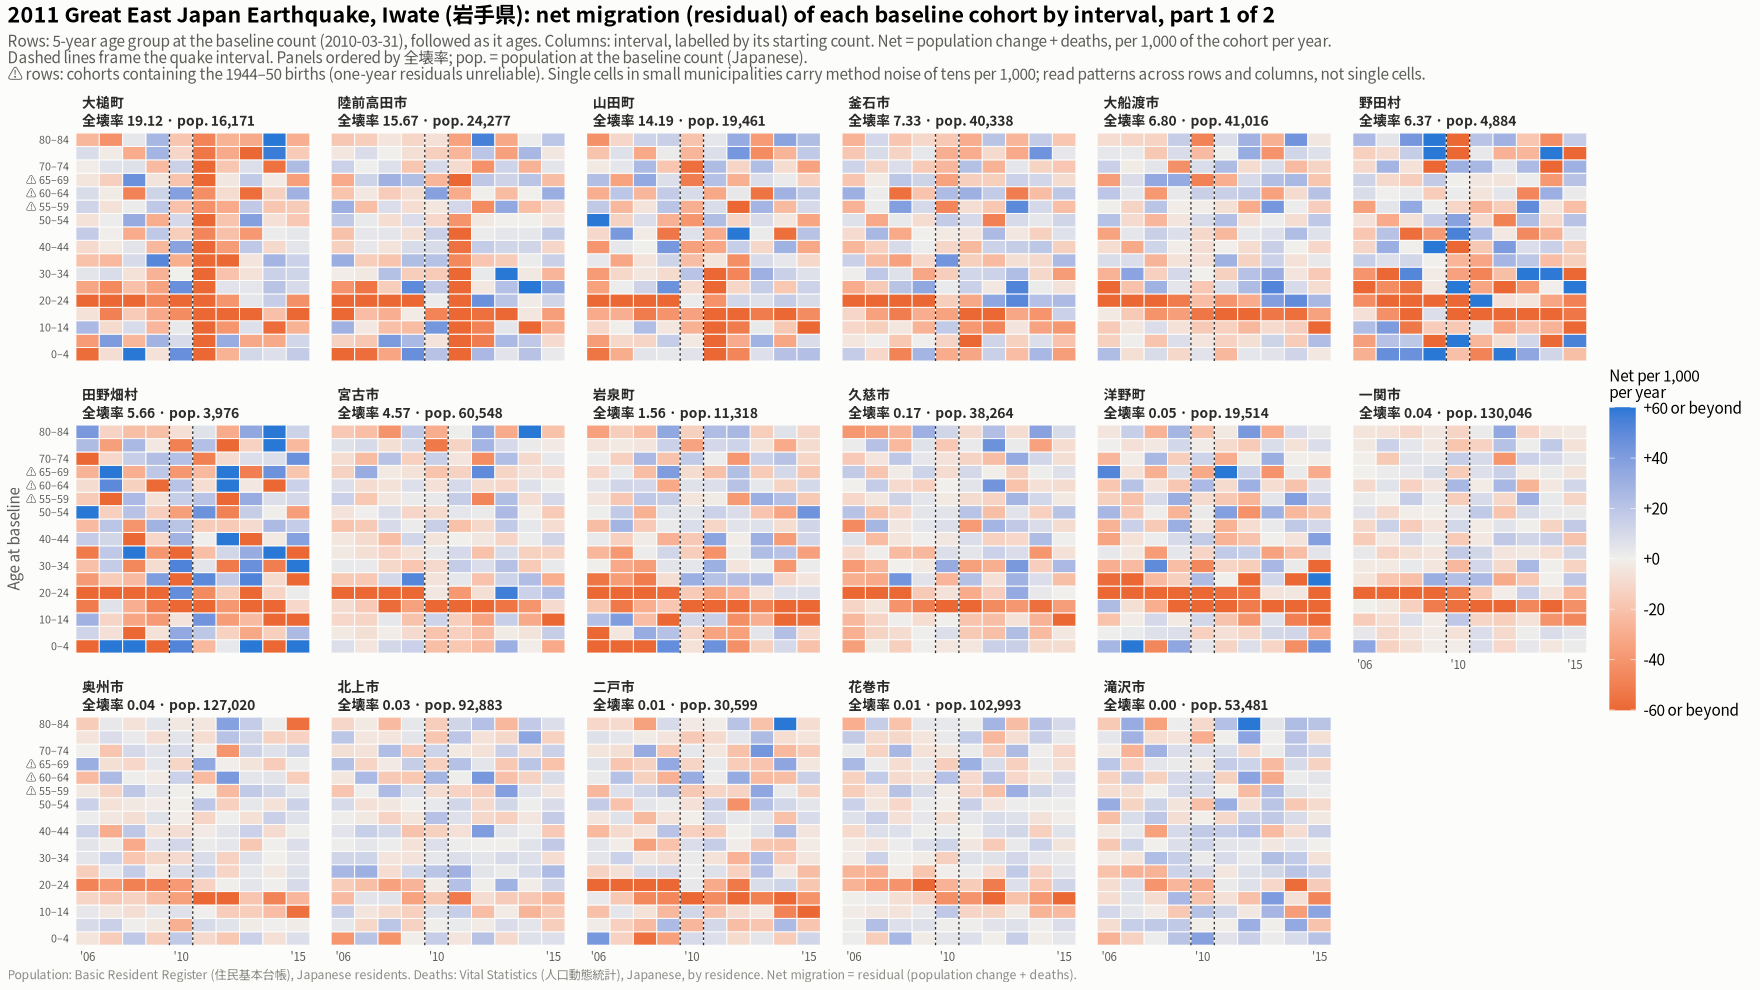

In [18]:
show_save(plot_heat("岩手県", 1), "07_heat_iwate_1", width = 18, height = 12)

### Figure 8: Iwate (岩手県), part 2 of 2

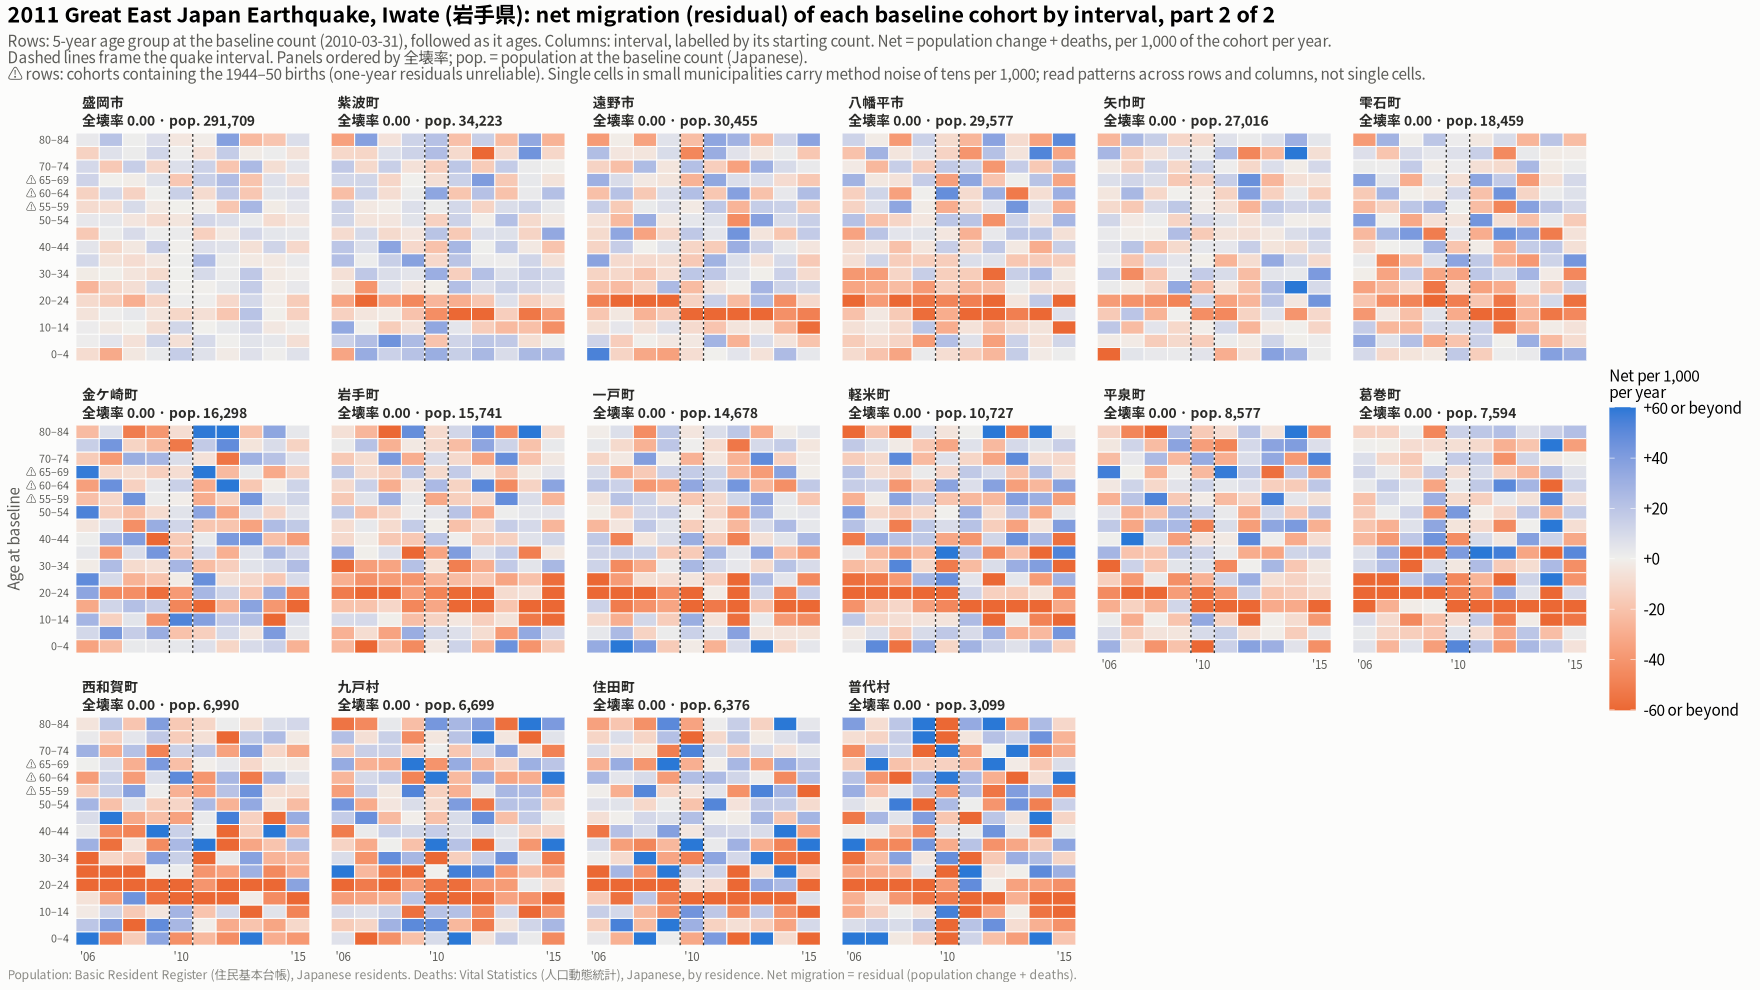

In [19]:
show_save(plot_heat("岩手県", 2), "08_heat_iwate_2", width = 18, height = 12)

### Figure 9: Miyagi (宮城県), part 1 of 2

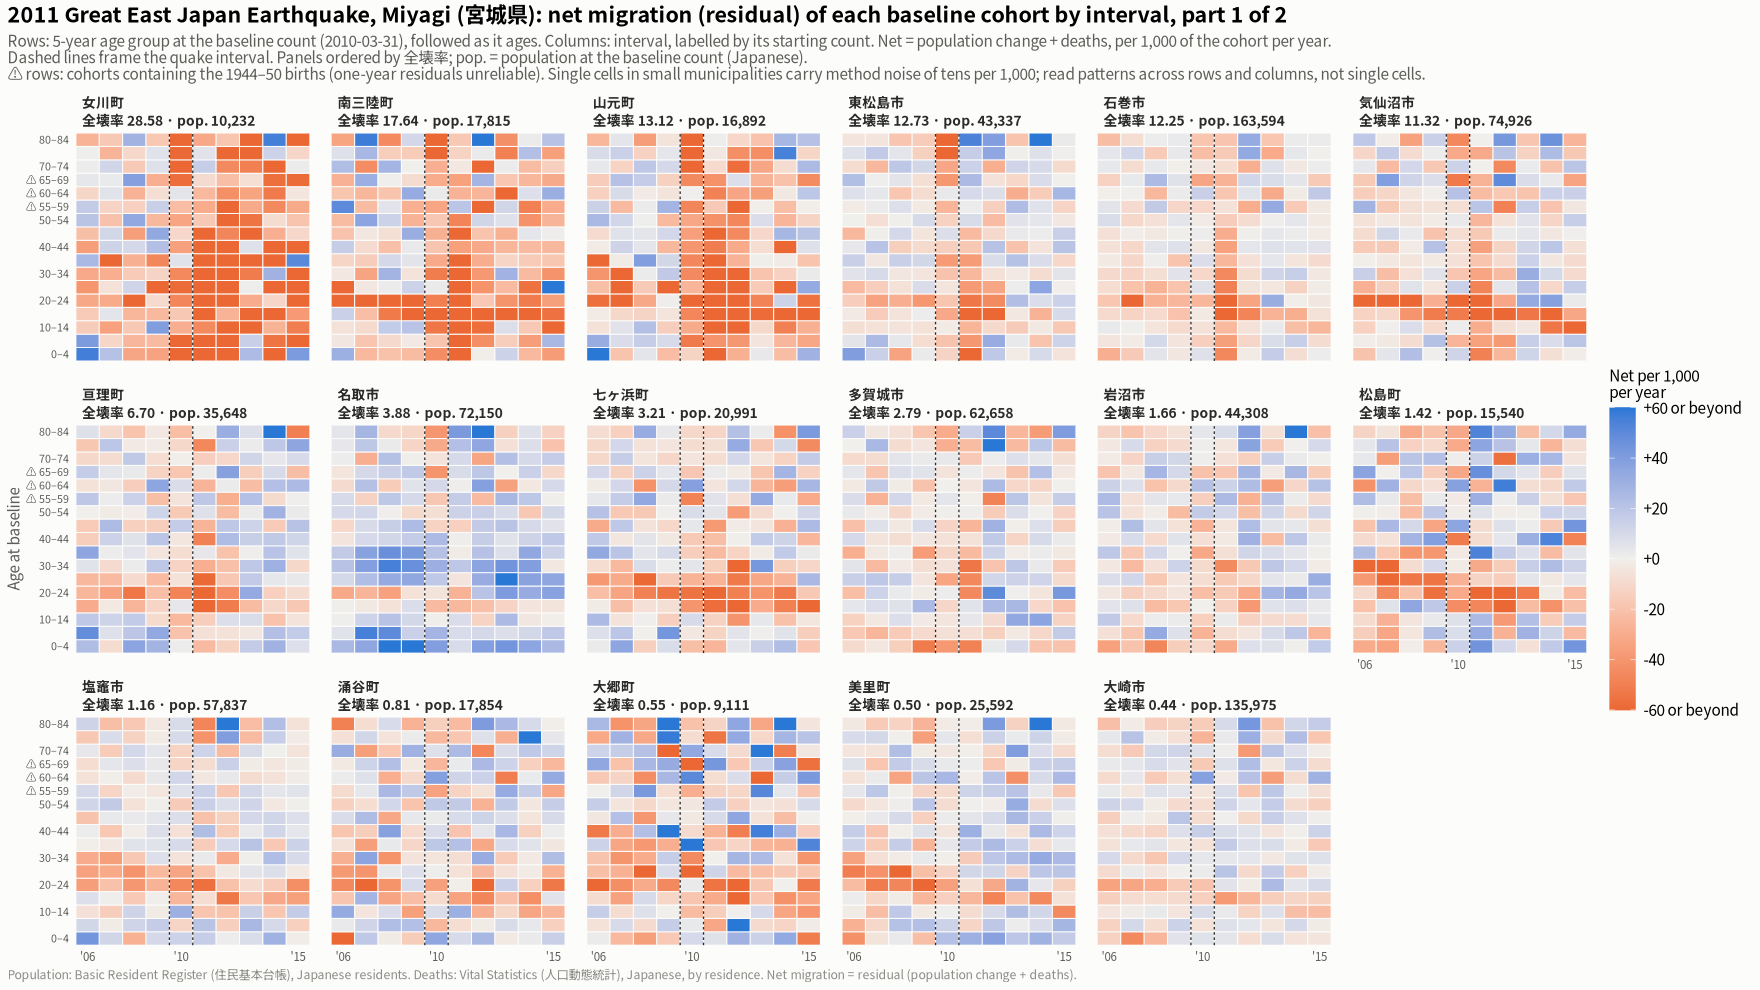

In [20]:
show_save(plot_heat("宮城県", 1), "09_heat_miyagi_1", width = 18, height = 12)

### Figure 10: Miyagi (宮城県), part 2 of 2

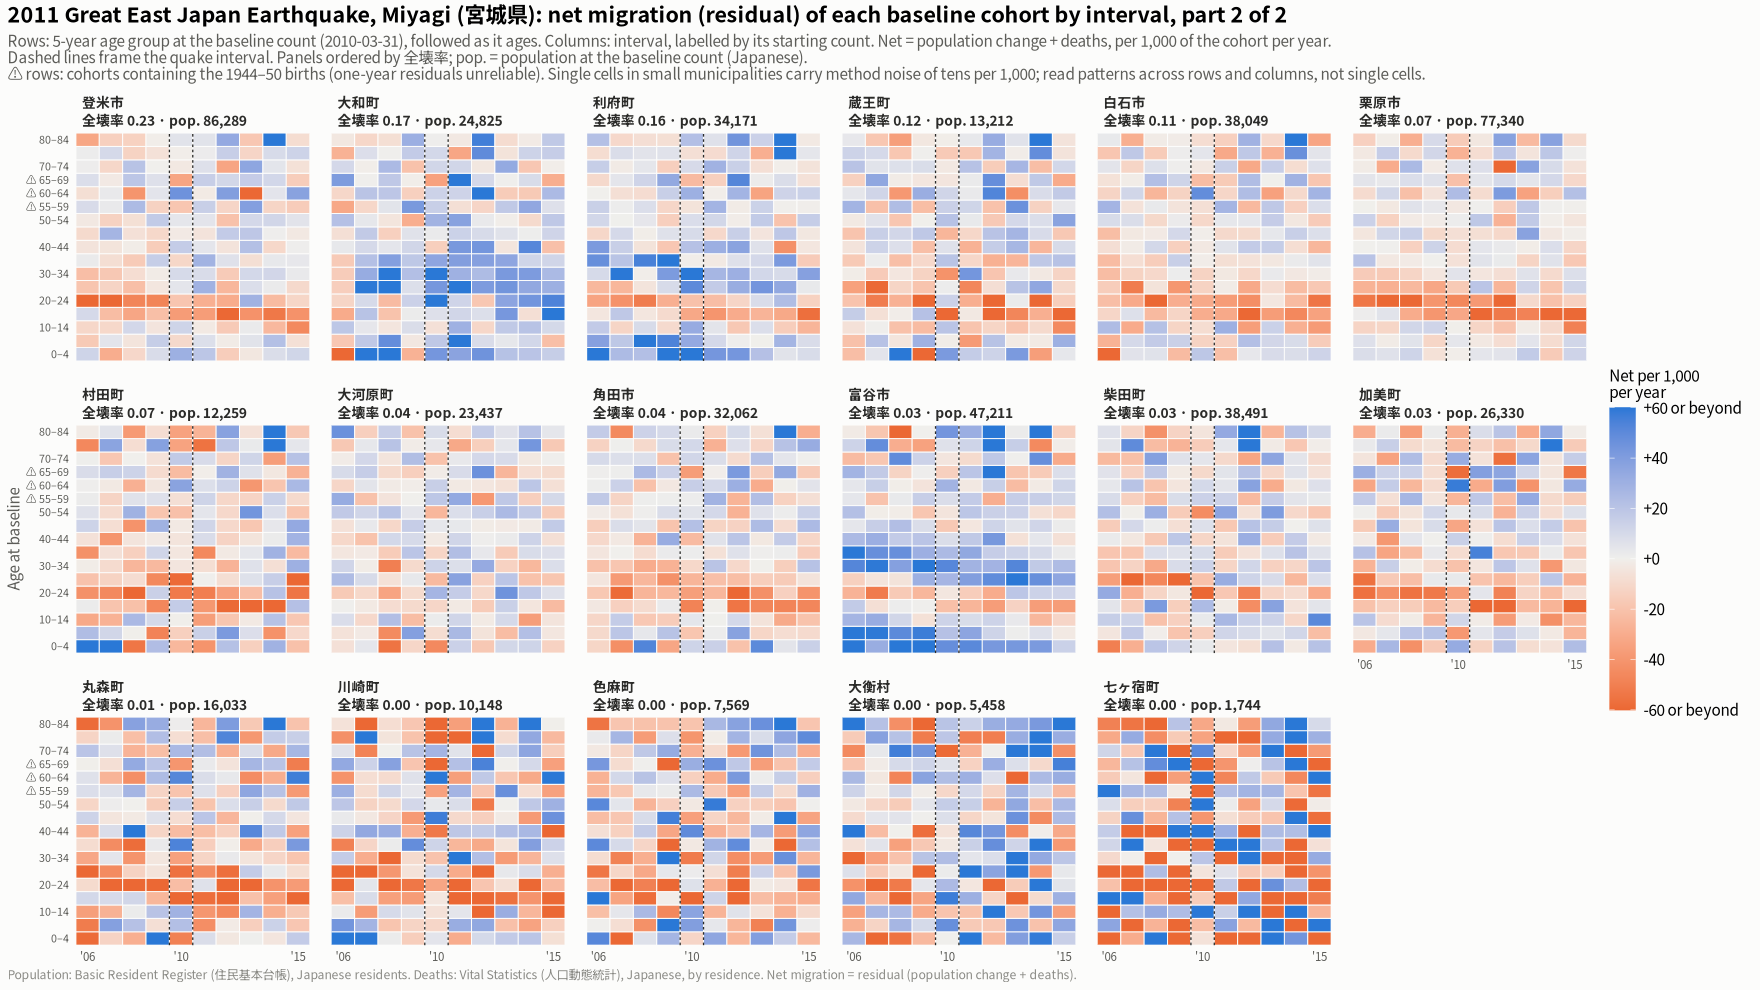

In [21]:
show_save(plot_heat("宮城県", 2), "10_heat_miyagi_2", width = 18, height = 12)

### Figure 11: Fukushima (福島県), part 1 of 4

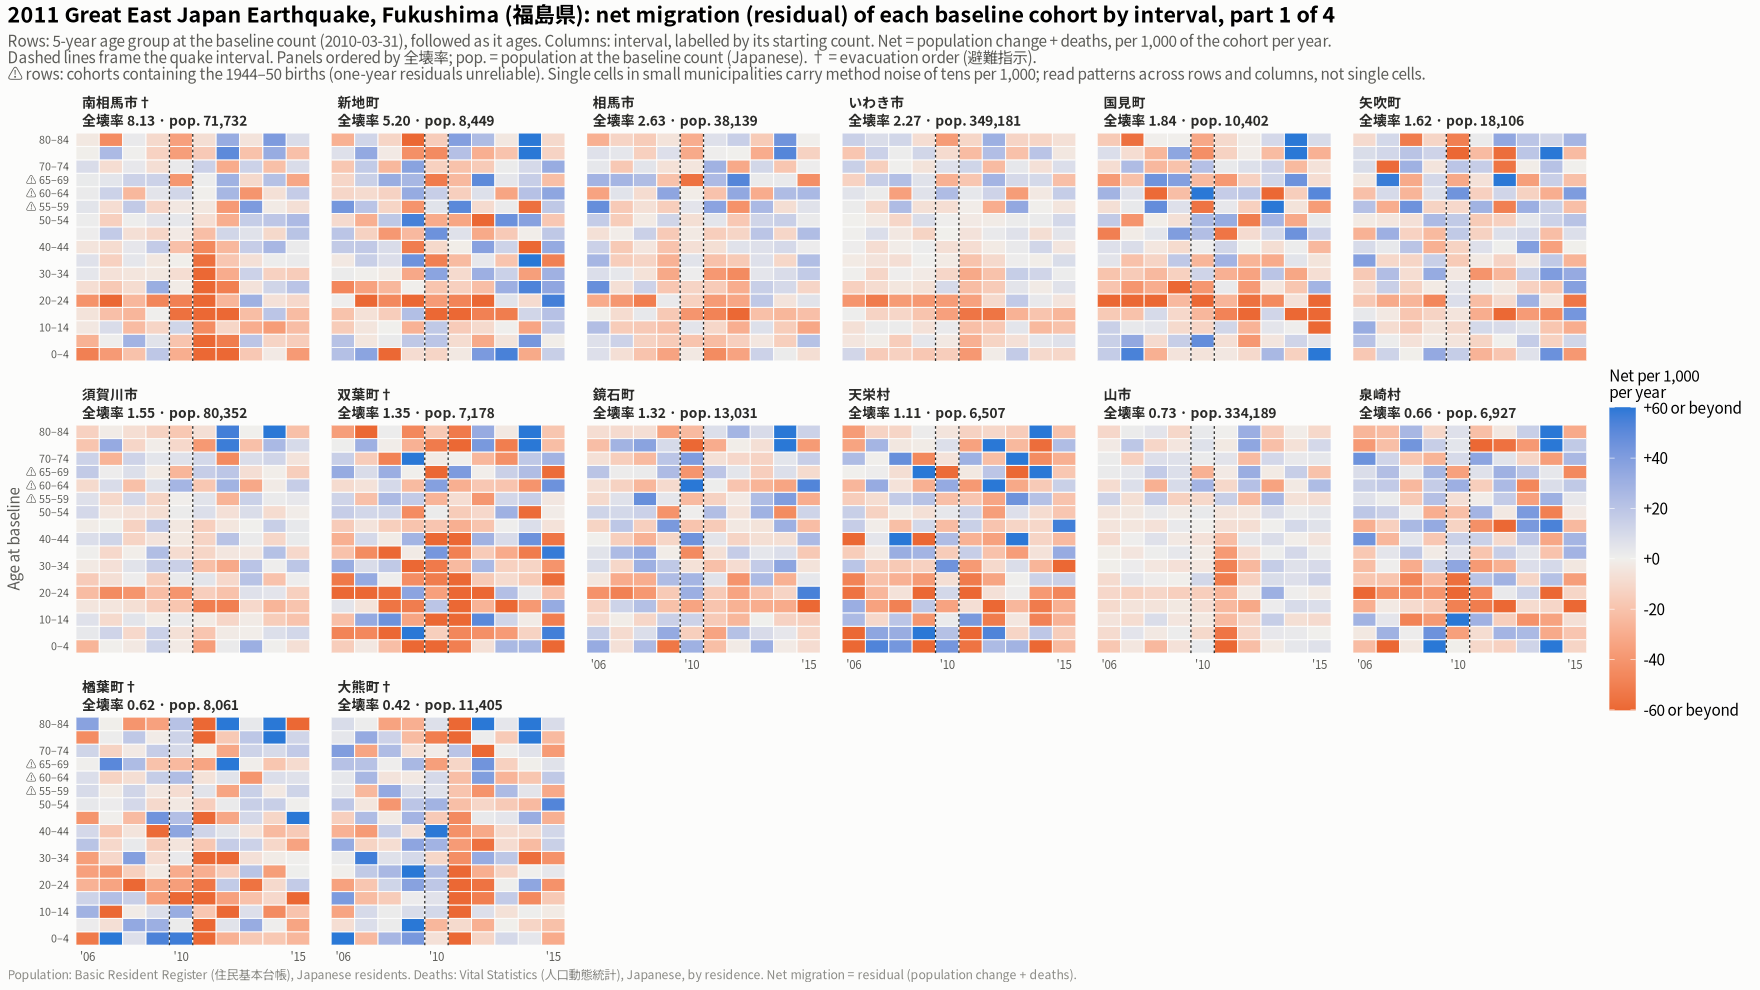

In [22]:
show_save(plot_heat("福島県", 1), "11_heat_fukushima_1", width = 18, height = 12)

### Figure 12: Fukushima (福島県), part 2 of 4

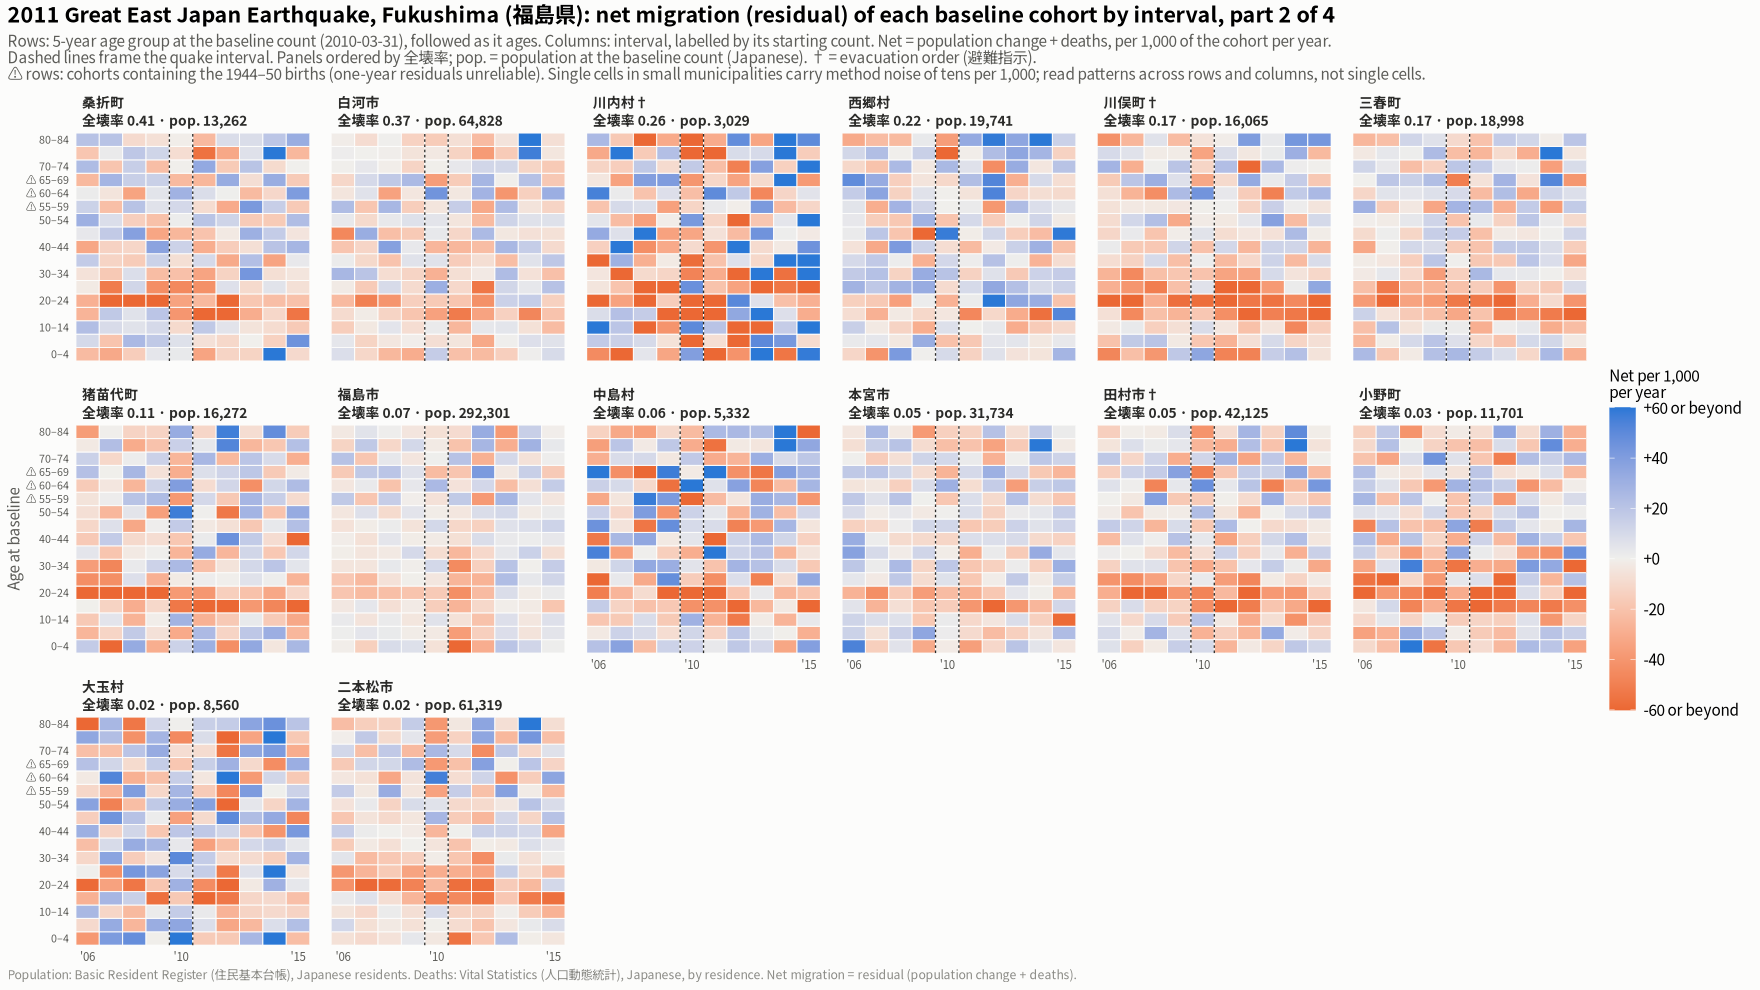

In [23]:
show_save(plot_heat("福島県", 2), "12_heat_fukushima_2", width = 18, height = 12)

### Figure 13: Fukushima (福島県), part 3 of 4

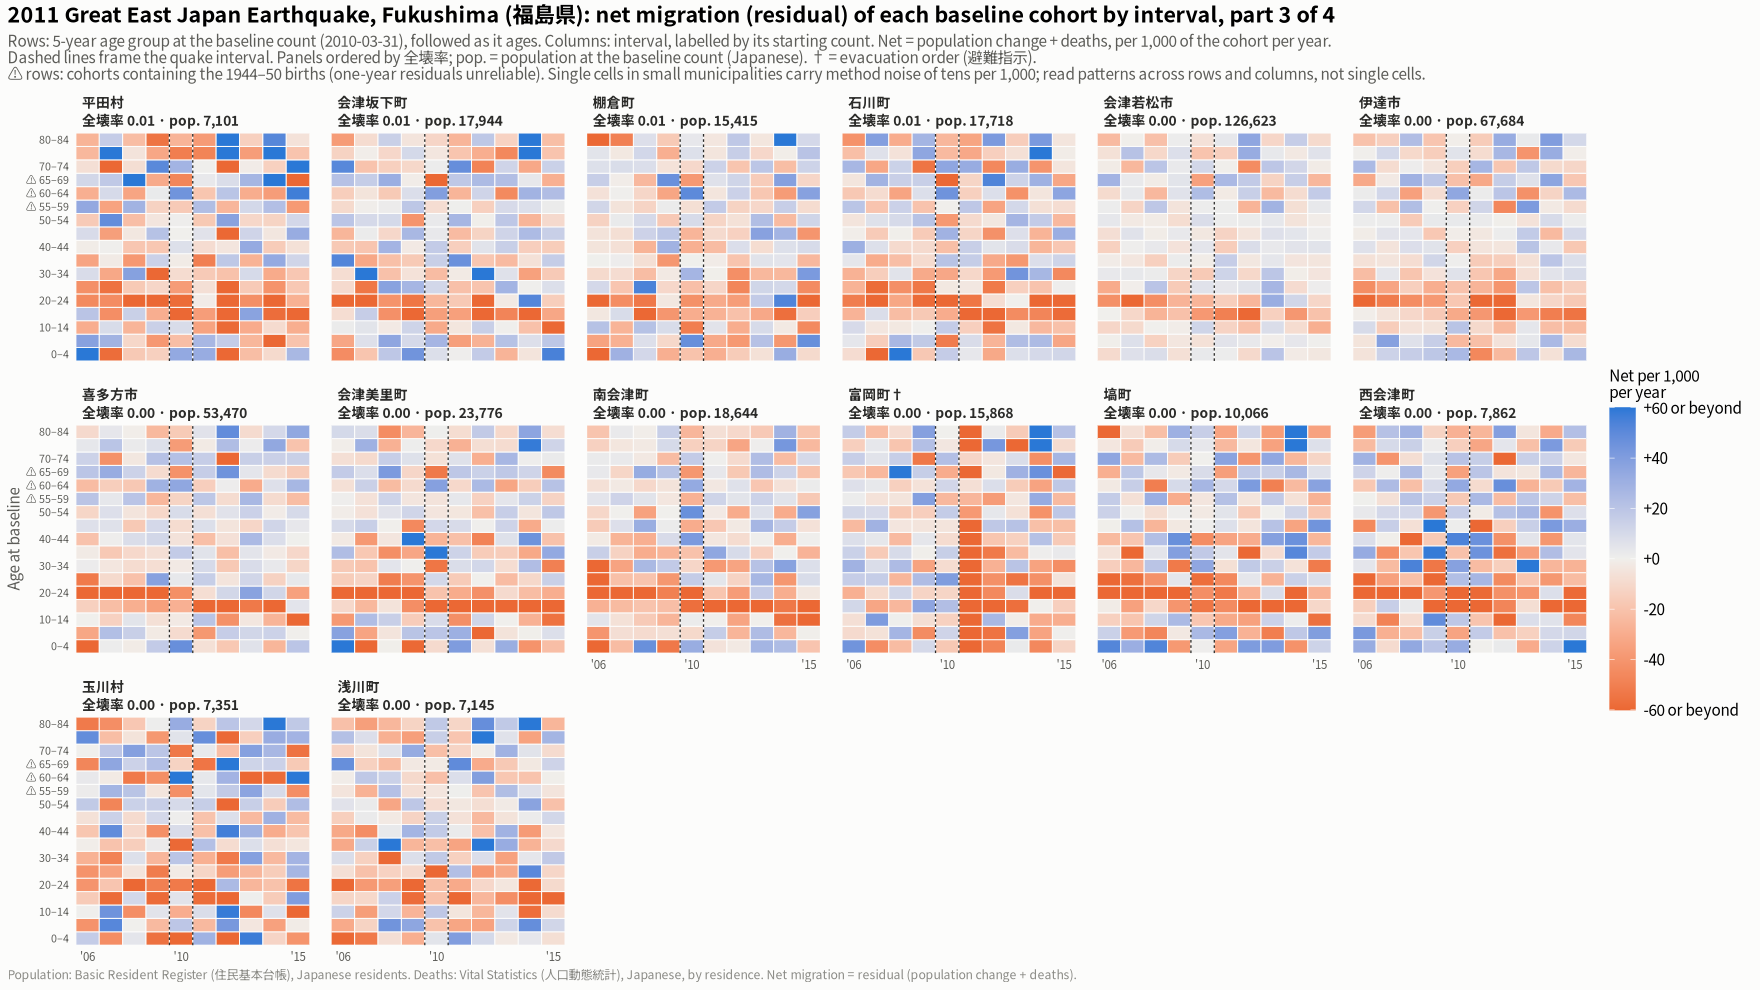

In [24]:
show_save(plot_heat("福島県", 3), "13_heat_fukushima_3", width = 18, height = 12)

### Figure 14: Fukushima (福島県), part 4 of 4

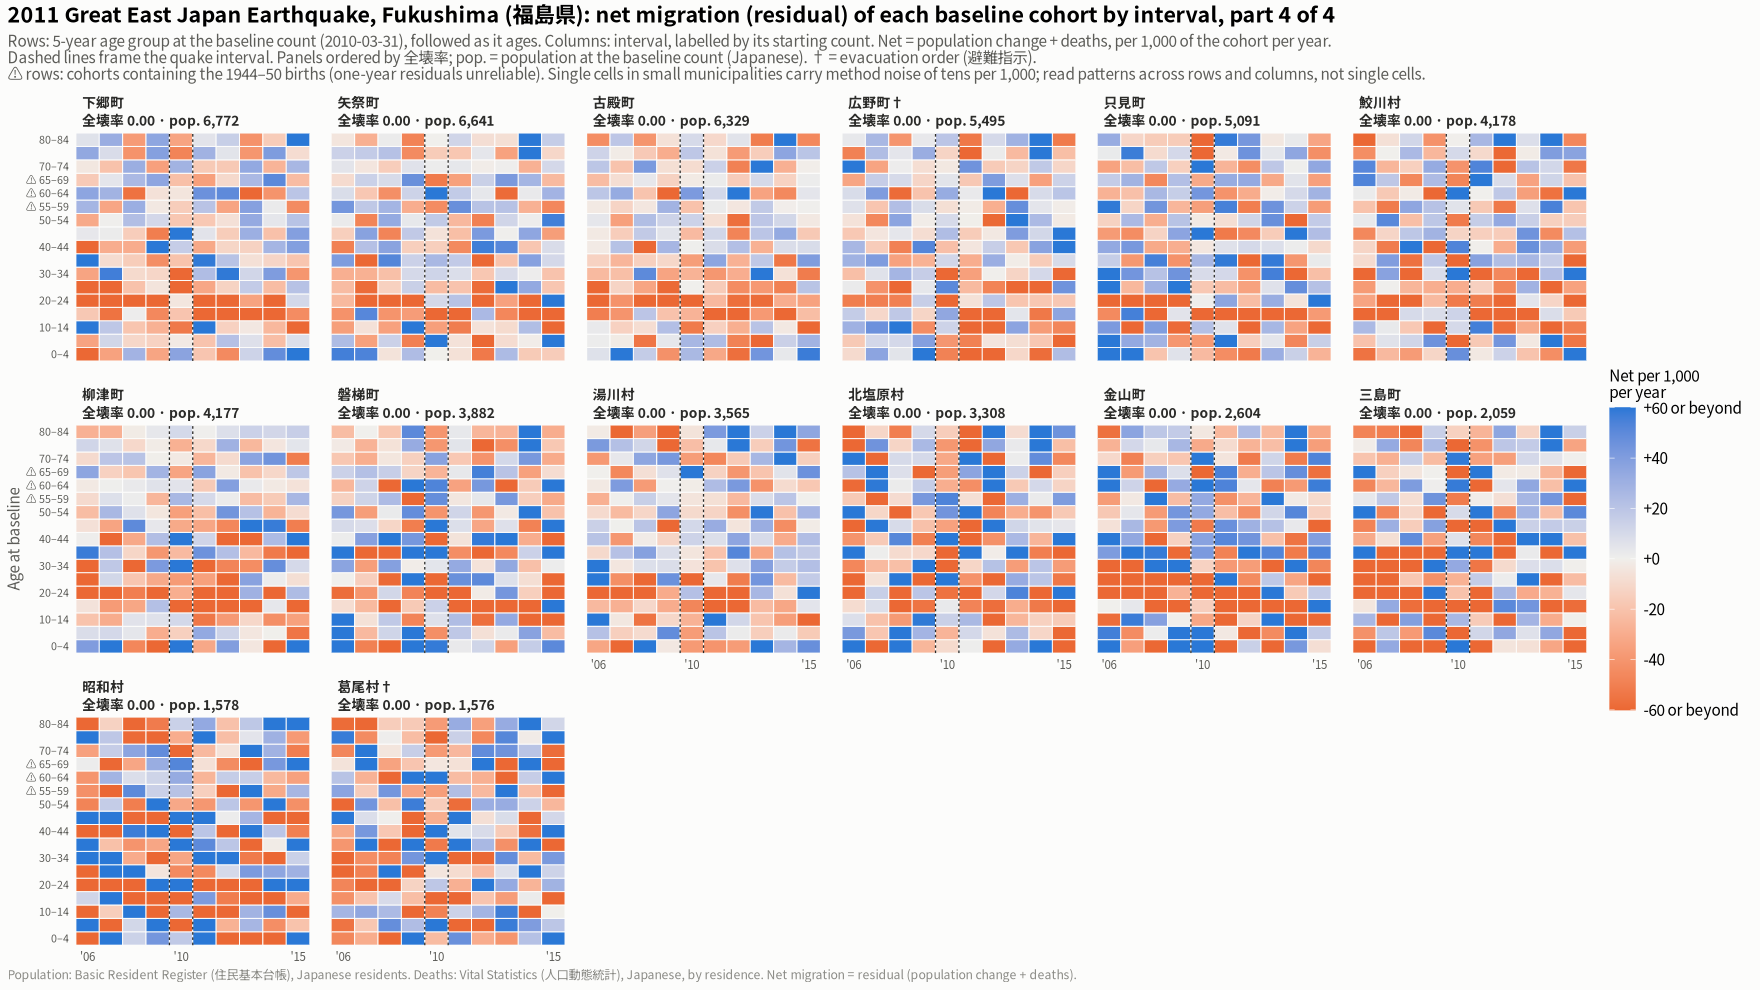

In [25]:
show_save(plot_heat("福島県", 4), "14_heat_fukushima_4", width = 18, height = 12)

### Figure 15: Kumamoto (熊本県), part 1 of 3

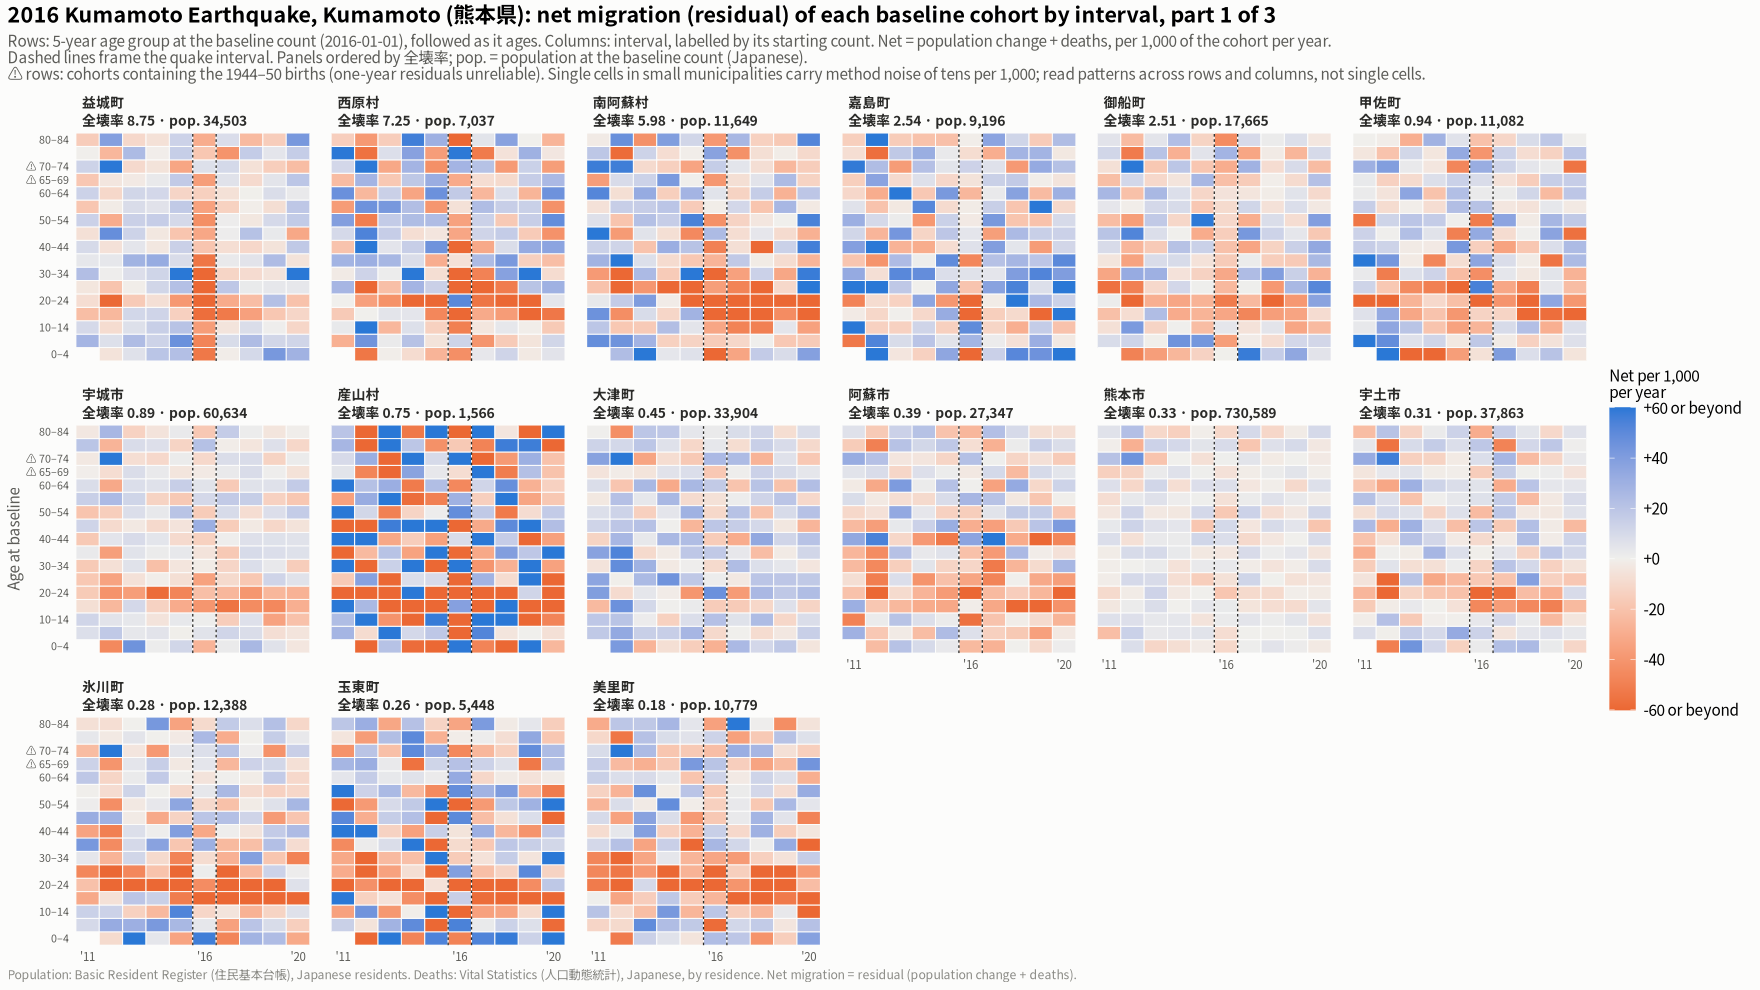

In [26]:
show_save(plot_heat("熊本県", 1), "15_heat_kumamoto_1", width = 18, height = 12)

### Figure 16: Kumamoto (熊本県), part 2 of 3

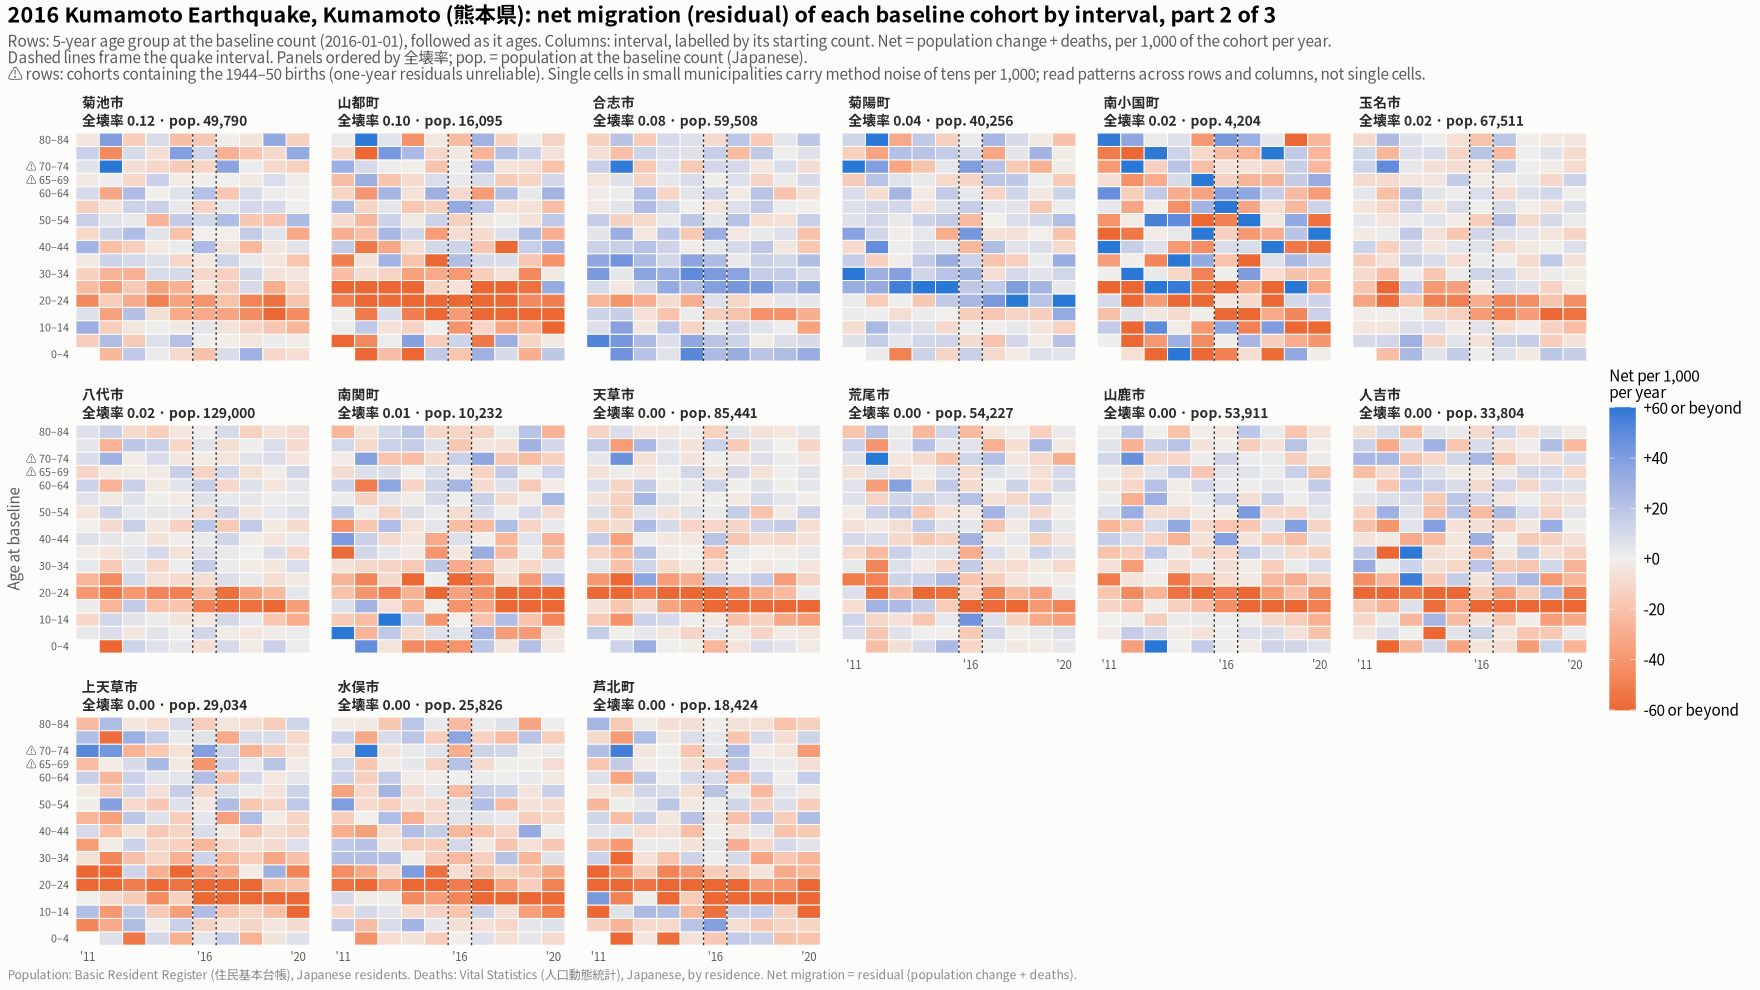

In [27]:
show_save(plot_heat("熊本県", 2), "16_heat_kumamoto_2", width = 18, height = 12)

### Figure 17: Kumamoto (熊本県), part 3 of 3

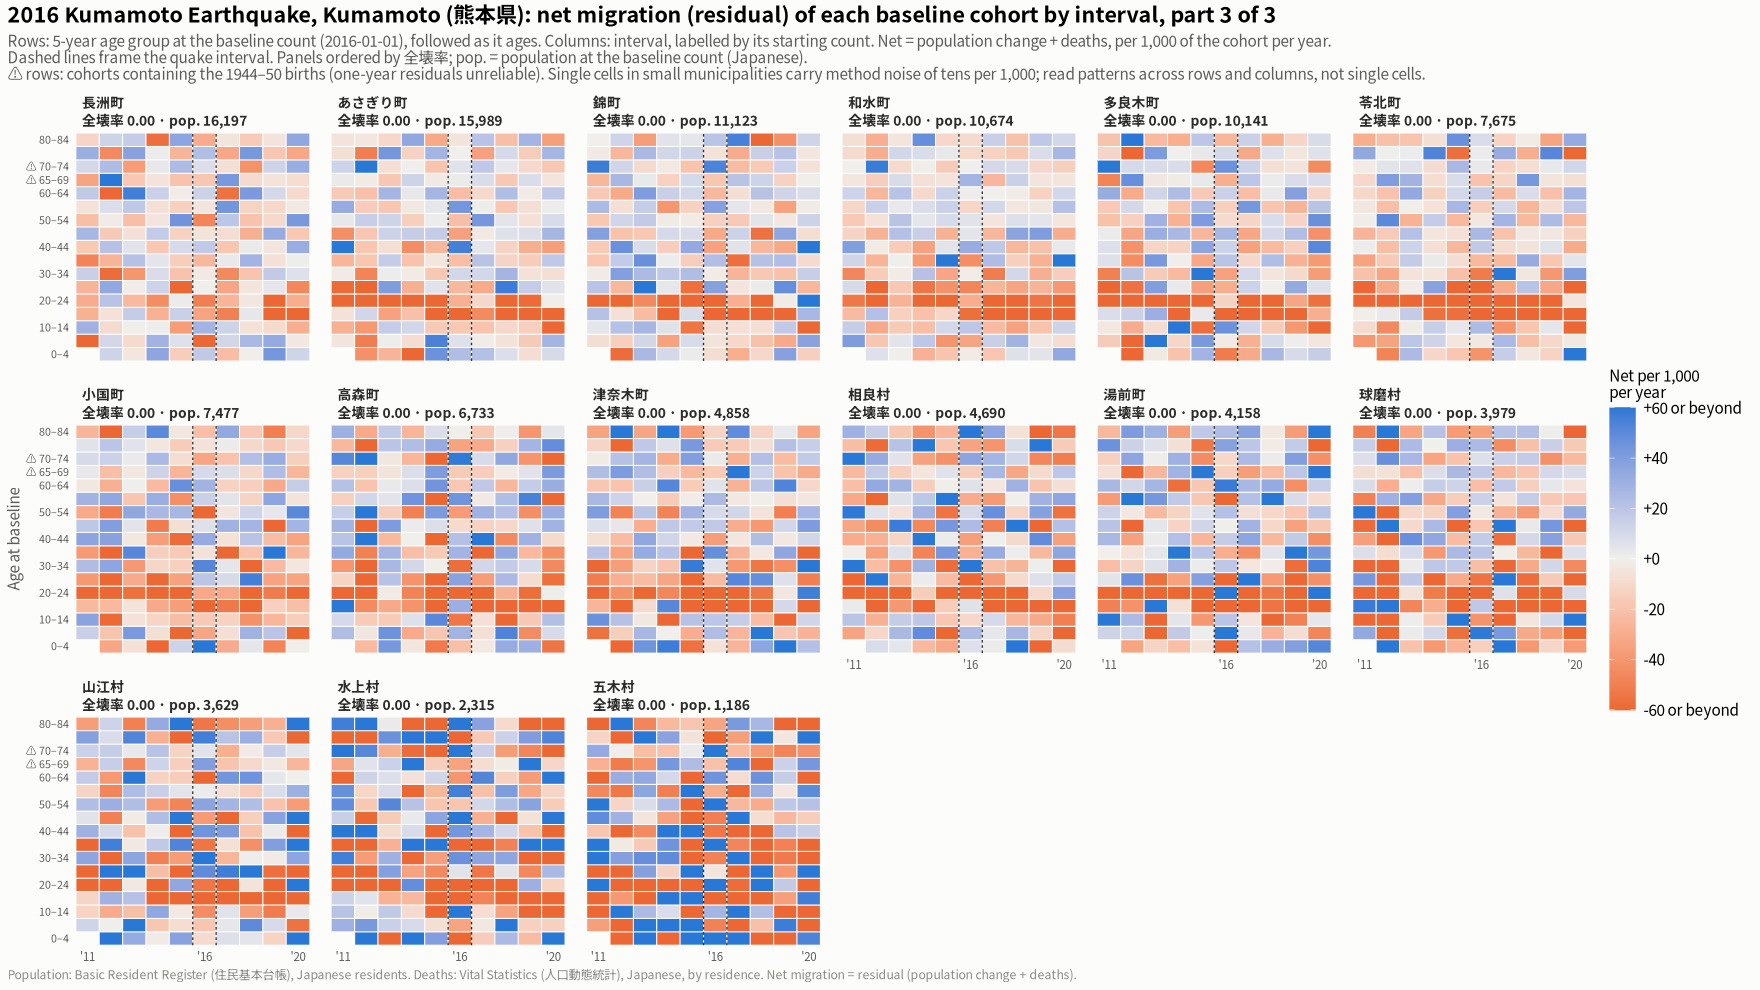

In [28]:
show_save(plot_heat("熊本県", 3), "17_heat_kumamoto_3", width = 18, height = 12)